# 0.0 Imports

In [34]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


from math import ceil
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, GroupKFold
from sklearn.ensemble import RandomForestRegressor
from boruta import BorutaPy

from sklearn.metrics import r2_score

from scipy.stats import chi2_contingency

# 0.1 Funções

In [30]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y)
    chi2   = chi2_contingency(tabela)[0]
    n      = tabela.values.sum()
    r, k   = tabela.shape

    phi2       = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr     = r - (r - 1) ** 2 / (n - 1)
    k_corr     = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


# 0.2 Loading DataSet

In [2]:
df_raw = pd.read_excel('dataset/dataset_leite_fazenda_100_animais_900_dias.xlsx')

/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/lucas/.pyenv/versions/milk_env/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)


In [3]:
#verificação shape do dataset
print(df_raw.shape)

#primeira cópia df_raw
df = df_raw.copy()

df.head(10).sort_values(by=['Date'], ascending=True).T

(6100, 49)


,0,1,2,3,4,5,6,7,8,9
Farm_ID,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001,FARM_001
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001
Date,2024-01-01 00:00:00,2024-01-16 00:00:00,2024-01-31 00:00:00,2024-02-15 00:00:00,2024-03-01 00:00:00,2024-03-16 00:00:00,2024-03-31 00:00:00,2024-04-15 00:00:00,2024-04-30 00:00:00,2024-05-15 00:00:00
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow
Breed,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein,Holstein
Country,BR,BR,BR,BR,BR,BR,BR,BR,BR,BR
State,MG,MG,MG,MG,MG,MG,MG,MG,MG,MG
Region,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast,Southeast
Municipality,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa,Vicosa
Climate_Zone,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude,Tropical_Altitude


# 0.3 Baseline do Negócio

Quanto de CMS (Consumo de Matéria Seca) vai ser necessário para fornecer ao rebanho da fazenda nos próximos 180 dias.

boa previsão do leite -> boa previsão de consumo de MS -> investimento acertivo em volumoso -> economia de até 20% sobre o total da receita

CMS = (0,0185xPeso do animal) + (0,305xLitros do animal produzido)

In [4]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 1
# =================================================================

"""
    Cada linha é uma coleta de dados no campo. Cada coleta são de 15 em 15 dias. 
    180 dias equivale a 12 observações em campo, ou 12 linhas do dataset.
"""

print('='*60)

#numero de animais
numero_de_vacas = df['Cattle_ID'].nunique()
print(f'Número de animais: {numero_de_vacas} vacas')

print('='*60)

#peso vivo dos animais por dia
peso_vivo_total_diario = df.groupby('Date')['Weight_kg'].sum()
print(f'Peso vivo total dos animais: {peso_vivo_total_diario:}kg')

print('='*60)

#rolling pega a linha 0 até a linha 11, ou seja, 12 datas/coletas
#peso vivo acumulado dos animais nos proximos 180 dias
peso_vivo_180d_total = peso_vivo_total_diario.rolling(12, min_periods=1).sum()
print(f'Peso vivo total acumulado dos animais dos proximos 180 dias somados: {peso_vivo_180d_total:}kg')

print('='*60)
#CMS de matéria seca diária (3% do PV)
CMS = df.groupby('Date')['Weight_kg'].sum()*0.03
print(f'Consumo de Matérica seca por peso vivo por dia: {CMS}kg')

print('='*60)

#Consumo de matéria seca acumulada nos proximos 180 dias
CMS_180d_total = CMS.rolling(12, min_periods=1).sum()
print(f'CMS acumulado dos proximos 180 dias somados: {CMS_180d_total:}kg')

print('='*60)

Número de animais: 100 vacas
Peso vivo total dos animais: Date
2024-01-01    59520.9
2024-01-16    59732.4
2024-01-31    59799.7
2024-02-15    59874.5
2024-03-01    59988.5
               ...   
2026-04-20    63254.3
2026-05-05    63192.5
2026-05-20    63150.9
2026-06-04    63277.7
2026-06-19    63212.8
Name: Weight_kg, Length: 61, dtype: float64kg
Peso vivo total acumulado dos animais dos proximos 180 dias somados: Date
2024-01-01     59520.9
2024-01-16    119253.3
2024-01-31    179053.0
2024-02-15    238927.5
2024-03-01    298916.0
                ...   
2026-04-20    759360.6
2026-05-05    759324.6
2026-05-20    759160.4
2026-06-04    759170.3
2026-06-19    759022.3
Name: Weight_kg, Length: 61, dtype: float64kg
Consumo de Matérica seca por peso vivo por dia: Date
2024-01-01    1785.627
2024-01-16    1791.972
2024-01-31    1793.991
2024-02-15    1796.235
2024-03-01    1799.655
                ...   
2026-04-20    1897.629
2026-05-05    1895.775
2026-05-20    1894.527
2026-06-04    18

In [5]:
# =================================================================
# Simulando da forma mais simples: CMS = peso_vivo * 0.03% parte 2
# =================================================================

#consumo de materia natural silagem proximos 180 dias (kg)
CMN_180d = CMS_180d_total / 0.3

#custo de materia natural silagem proximos 180 dias (R$/kg = 0,20 ) (R$)
custo_CMN_180d = CMN_180d * 0.2

#custo acumulado de materia natural silagem proximos 180 dias
custo_CMN_180d.sum()
print(f'custo com matéria natural nos próximos 180 dias é de R${custo_CMN_180d.sum():.2f}')

custo com matéria natural nos próximos 180 dias é de R$826651.44


# 1.0 Criando os Target e Pré-limpeza

In [6]:
print(df.isna().sum())
df.shape

df1 = df.copy()

#tirando as colunas que resolvemos não trabalhar
df1 = df1.drop(['Lag_Mean_180_Days', 'Target_Milk_15_Days', 'Target_Milk_30_Days', 'Target_Milk_90_Days', 
                'Farm_ID', 'Breed', 'Country', 'State', 'Region', 'Municipality', 'Management_System', 
                'Lot', 'Milking_Interval_hrs', 'Housing_Score', 'Grazing_Duration_hrs', 'Climate_Zone', 'Feed_Type', 'Lactation_Status'], axis=1)


Farm_ID                          0
Cattle_ID                        0
Date                             0
Animal_Category                  0
Breed                            0
Country                          0
State                            0
Region                           0
Municipality                     0
Climate_Zone                     0
Management_System                0
Feed_Type                        0
Season                           0
Age_Days                         0
Age_Months                       0
Weight_kg                        0
Parity                           0
Lactation_Status                 0
Lactation_Stage                  0
Days_in_Milk                     0
Days_Since_Calving               0
Lot                              0
Milking_Frequency_per_day        0
Milking_Interval_hrs             0
Body_Condition_Score             0
Body_Condition_Class             0
Ambient_Temperature_C            0
Humidity_percent                 0
Temperature_Humidity

In [7]:
#apagando as linhas que contém NaN 
df1 = df1.dropna(subset = ['Target_Milk_180_Days', 'Lag_Mean_90_Days'])

df1.shape

(4300, 31)

In [8]:
aux = df1.groupby('Cattle_ID')['Milk_Yield_L'].count()
aux

Cattle_ID
CATTLE_001    43
CATTLE_002    43
CATTLE_003    43
CATTLE_004    43
CATTLE_005    43
              ..
CATTLE_096    43
CATTLE_097    43
CATTLE_098    43
CATTLE_099    43
CATTLE_100    43
Name: Milk_Yield_L, Length: 100, dtype: int64

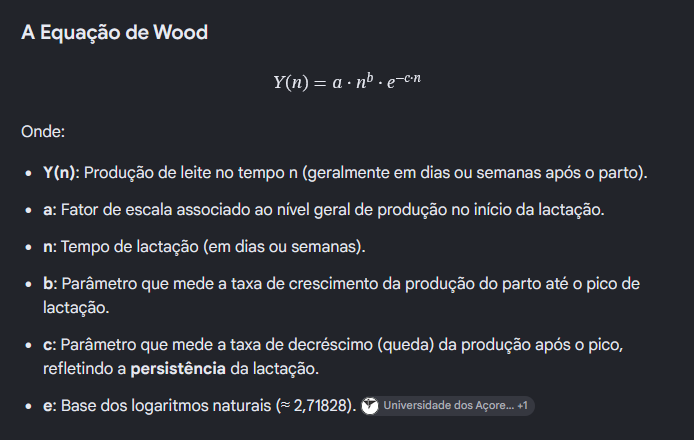

0-12 observações (TREINO)
13-24 (não posso usar)
25 - 30 (VAL) ->>>>> prever 42 <<<<<- 
31 - 36 (não posso usar)
37 - 43 (TESTE) ->>>> 55


10 dias de previsão

0-60 treino

71-80 val

85-100 teste

-----------                             produção real 20 Litros    target 75 = Milk_Yield_L 85            
 75 eu ja sei oq aconteceu no dia 85 -> meu treino ficou roubado
0-80 treino 

            MIlk_Yield_L: 20 litros
dia 85 -> produção real 20 Litros
85-100 teste ->> 95-110

# 2.0 Separação Treino, Test, Val e Target

In [9]:
#garantindo que as colunas sejam datas
df1['Date'].info()

#lista as datas distintas, em ordem
registros = df1['Date'].sort_values().unique()
registros

#os ultimos o primeiro registro do grupo de dados test, de trás pra frente
registros_test = registros[-7]
registros_test

X_train = df1.loc[(df1['Date'] < registros_test), :].copy()

X_test = df1.loc[(df1['Date'] >= registros_test), :].copy()

#treino e teste separados, ainda falta val e tirar as interseções

#=======================================================================================

#separando treino e val
aux_1 = X_train['Date'].sort_values().unique()
registros_train = aux_1[11]

X_val = X_train.loc[(X_train['Date'] > registros_train), :].reset_index(drop=True)

X_train = X_train.loc[(X_train['Date'] <= registros_train), :].reset_index(drop=True)

#=======================================================================================

#tirando um pedaço do inicio de val (12 posições) e um pedaço do final de val (6)
aux_2 = X_val['Date'].sort_values().unique()
registros_val = aux_2[11]

X_val = X_val.loc[(X_val['Date'] > registros_val), :].reset_index(drop=True)


aux_3 = X_val['Date'].sort_values().unique()
registros_val_2 = aux_3[-6]

X_val = X_val.loc[(X_val['Date'] < registros_val_2), :].reset_index(drop=True)

X_val['Date'].nunique()

<class 'pandas.Series'>
Index: 4300 entries, 6 to 6087
Series name: Date
Non-Null Count  Dtype         
--------------  -----         
4300 non-null   datetime64[us]
dtypes: datetime64[us](1)
memory usage: 67.2 KB


6

In [10]:
#separando X de y

y_train = X_train['Target_Milk_180_Days']
X_train = X_train.drop('Target_Milk_180_Days', axis=1)

y_test = X_test['Target_Milk_180_Days']
X_test = X_test.drop('Target_Milk_180_Days', axis=1)

y_val = X_val['Target_Milk_180_Days']
X_val = X_val.drop('Target_Milk_180_Days', axis=1)

In [11]:
#verificando se as divisões foram corretas em relação a dimensão

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

print(X_val.shape)
print(y_val.shape)

(1200, 30)
(1200,)
(700, 30)
(700,)
(600, 30)
(600,)


In [12]:
#concantenando x e y train para fazer E.D.A

df_train = pd.concat([X_train, y_train], axis=1)

# 3.0 Analisando os Dados

In [13]:
#conferindo celulas vazias e duplicadas
print(df_train.isna().sum())
print(df_train.shape)
print(df_train.duplicated().sum())

Cattle_ID                     0
Date                          0
Animal_Category               0
Season                        0
Age_Days                      0
Age_Months                    0
Weight_kg                     0
Parity                        0
Lactation_Stage               0
Days_in_Milk                  0
Days_Since_Calving            0
Milking_Frequency_per_day     0
Body_Condition_Score          0
Body_Condition_Class          0
Ambient_Temperature_C         0
Humidity_percent              0
Temperature_Humidity_Index    0
Heat_Stress_Class             0
Health_Status                 0
Days_Since_Health_Event       0
Rumination_Time_hrs           0
Resting_Hours                 0
Water_Intake_L                0
Walking_Distance_km           0
Previous_Week_Avg_Yield       0
Milk_Yield_L                  0
Dry_Matter_Intake_kg          0
Lag_Mean_15_Days              0
Lag_Mean_30_Days              0
Lag_Mean_90_Days              0
Target_Milk_180_Days          0
dtype: i

# 4.0 Análise Descritiva

## 4.1 Variáveis Numéricas

In [14]:
#separando os dados numéricos
num_atributos = df_train.select_dtypes(include=['float64', 'int'])
num_atributos.T

,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Age_Days,1097.00,1112.00,1127.00,1142.00,1157.00,1172.00,1187.00,1202.00,1217.00,1232.00,...,352.00,367.00,382.00,397.00,412.00,427.00,442.00,457.00,472.00,487.00
Age_Months,36.00,36.50,37.00,37.50,38.00,38.50,39.00,39.50,40.00,40.50,...,11.60,12.10,12.60,13.00,13.50,14.00,14.50,15.00,15.50,16.00
Weight_kg,619.60,617.90,619.00,628.30,624.50,629.60,619.10,620.20,604.00,593.00,...,371.80,365.00,377.60,389.70,392.50,401.80,406.80,418.90,434.50,435.20
Parity,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00,2.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_in_Milk,260.00,275.00,290.00,0.00,0.00,0.00,0.00,0.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Days_Since_Calving,260.00,275.00,290.00,305.00,320.00,335.00,350.00,365.00,15.00,30.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Milking_Frequency_per_day,3.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,3.00,3.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Body_Condition_Score,3.44,3.76,3.67,3.37,3.40,3.27,3.68,3.55,3.15,3.20,...,3.42,3.23,3.42,3.34,3.33,3.28,3.29,3.28,3.40,3.35
Ambient_Temperature_C,23.72,23.97,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,...,22.70,24.29,24.62,22.96,21.57,22.16,18.23,20.42,17.81,17.47
Humidity_percent,76.05,89.44,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,...,84.96,78.67,77.74,76.08,73.65,71.80,75.67,66.70,69.08,70.70


In [15]:
#tendencia central - média e mediana

ct1 = pd.DataFrame(num_atributos.mean()).T

ct2 = pd.DataFrame(num_atributos.median()).T

#dispersão: std, minimo, maximo, range, skewness, kurtosis

d1 = pd.DataFrame(num_atributos.std()).T
d2 = pd.DataFrame(num_atributos.min()).T
d3 = pd.DataFrame(num_atributos.max()).T
d4 = pd.DataFrame(num_atributos.max() - num_atributos.min()).T
d5 = pd.DataFrame(num_atributos.skew()).T
d6 = pd.DataFrame(num_atributos.kurtosis()).T

#concatenar os resultados
m = pd.concat([ct1, ct2, d1, d2, d3, d4, d5, d6], axis=0).T.reset_index()

#trocando nome das colunas
m.columns = ['atributos', 'mean', 'median', 'std', 'min', 'max', 'range', 'skew', 'kurtosis']
m.style.background_gradient(cmap='Blues')

#skew:
#-0.5 a 0.5: pouco assimetria
#-1 a -0,5: assimetrica moderadamente
#0.5 a 1: assimetrica moderadamente
#-1 < e > 1: assimetria forte

,atributos,mean,median,std,min,max,range,skew,kurtosis
0,Age_Days,1634.560000,1651.500000,660.429087,282.000000,2797.000000,2515.000000,-0.192298,-0.843483
1,Age_Months,53.702250,54.250000,21.697672,9.300000,91.900000,82.600000,-0.192437,-0.843509
2,Weight_kg,607.372417,628.250000,81.556840,327.400000,738.300000,410.900000,-1.235916,1.308511
3,Parity,2.443333,3.000000,1.423075,0.000000,5.000000,5.000000,-0.191321,-0.770640
4,Days_in_Milk,97.397500,71.000000,97.302086,0.000000,300.000000,300.000000,0.598008,-1.013171
5,Days_Since_Calving,151.042500,135.000000,118.719372,0.000000,365.000000,365.000000,0.261187,-1.297977
6,Milking_Frequency_per_day,1.750833,2.000000,1.214487,0.000000,3.000000,3.000000,-0.513228,-1.325061
7,Body_Condition_Score,3.353250,3.380000,0.236980,2.630000,4.010000,1.380000,-0.247915,-0.445687
8,Ambient_Temperature_C,21.660000,22.430000,2.483792,17.470000,24.620000,7.150000,-0.568358,-1.148973
9,Humidity_percent,75.878333,75.860000,6.171315,66.700000,89.440000,22.740000,0.698921,-0.062933


## 4.2 Variáveis Categóricas

In [16]:
cat_atributos = df_train.select_dtypes(exclude=['float64', 'int', 'datetime64'])

print(cat_atributos.columns)
print(cat_atributos.nunique())
cat_atributos.T

Index(['Cattle_ID', 'Animal_Category', 'Season', 'Lactation_Stage',
       'Body_Condition_Class', 'Heat_Stress_Class', 'Health_Status'],
      dtype='str')
Cattle_ID               100
Animal_Category           2
Season                    3
Lactation_Stage           5
Body_Condition_Class      3
Heat_Stress_Class         3
Health_Status             4
dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,1190,1191,1192,1193,1194,1195,1196,1197,1198,1199
Cattle_ID,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,CATTLE_001,...,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100,CATTLE_100
Animal_Category,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,Cow,...,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer,Heifer
Season,Autumn,Autumn,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,...,Autumn,Autumn,Autumn,Winter,Winter,Winter,Winter,Winter,Winter,Spring
Lactation_Stage,Late,Late,Late,Dry,Dry,Dry,Dry,Dry,Early,Early,...,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation,Pre_Lactation
Body_Condition_Class,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok,...,ok,ok,ok,ok,ok,ok,ok,ok,ok,ok
Heat_Stress_Class,Moderate,Moderate,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,...,Mild,Moderate,Moderate,Mild,Mild,Mild,No_Stress,No_Stress,No_Stress,No_Stress
Health_Status,Healthy,Healthy,Healthy,Healthy,Lameness,Lameness,Healthy,Healthy,Healthy,Healthy,...,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy,Healthy


## 4.3 Hipóteses

1. Vacas com estágio de lactação médio tem maior produtividade diários que vacas com estágio cedo e tardio
2. Vacas com idade mediana produz mais leite que as demais faixas de idade
3. Vacas mais pesadas tendem a produzir mais leite
4. Vacas com número de partos mediano produz mais leite que as demais faixas de numero de partos
5. Vacas que ingerem mais águas produzem mais litros leite diários
6. Vacas que andam mais, produzem menos litros de leite diários
7. Vacas que descansam mais tem mais produtividade litros de leite diários
8. Vacas no outono produzem mais litros de leite diariamente
9. Na maior parte das vezes, vacas com média diária da semana anterior com maiores produtividades, tendem a produzir maior litros de leite
10. Vacas com score corporal 3 tendem a ter maior produtividade diária
11. Vacas com intervalo de ordenha de 8h tendem a ter maior produtividade diária
12. Vacas saudáveis tendem a produzir mais litros de leite 

# 5.0 Análise Exploratória de Dados (E.D.A)

## 5.1 Análise Univariada

### 5.1.1 Análise Variável Resposta

<Axes: xlabel='Target_Milk_180_Days', ylabel='Count'>

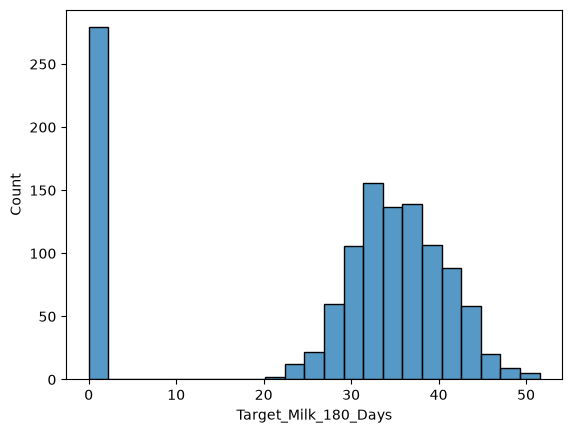

In [17]:
#analisando a variavel resposta

sns.histplot(data=df_train, x='Target_Milk_180_Days')

### 5.1.2 Análise Univariada Numéricas

## Bloco 1 — Importações e configuração

- **`TARGET`**: a coluna que se quer prever.
- **`GRUPO`**: a coluna que identifica cada vaca. Usada para separar a validação cruzada por animal.
- **`num_cols`**: as colunas numéricas, **sem o alvo**. Como o alvo é numérico, sem o `if c != TARGET` ele entraria na lista e seria comparado consigo mesmo. `Cattle_ID` é texto, então já fica de fora.
- **`GroupKFold(n_splits=5)`**: divide os dados em 5 partes, garantindo que **todas as linhas de uma vaca fiquem na mesma parte**.
- **`arvore`**: a árvore que mede relações curvas. Está aqui fora do loop porque a configuração é a mesma para todas as features.
    - **`max_depth=3`**: no máximo 3 níveis de perguntas, o que dá até 8 faixas.
    - **`min_samples_leaf=20`**: cada faixa precisa de pelo menos 20 linhas, para a árvore não criar faixas para pontos isolados.

> **Por que separar por vaca.** Cada vaca aparece em várias linhas (uma por coleta). Com um `KFold` comum, linhas da mesma vaca caem no treino e no teste ao mesmo tempo, e a árvore "reconhece" a vaca em vez de aprender a relação. É como uma prova com questões que o aluno já viu na lista de exercícios: a nota sobe, mas não mede o aprendizado. Com `GroupKFold`, a árvore é testada em vacas que ela nunca viu.


## Bloco 2 — O loop: calcular as métricas de cada feature

- **`dados = ...dropna()`**: pega a feature, o alvo e o ID da vaca, e remove a linha inteira se faltar qualquer um. Assim as três colunas ficam alinhadas linha a linha.
- **`x`**: a feature com colchete duplo, para ser DataFrame (formato que o sklearn exige).
- **`y`, `g`**: o alvo e o ID da vaca, como Series.
- **`rho, _ = stats.spearmanr(...)`**: a função devolve dois valores, a correlação e o p-valor. O `_` é a convenção do Python para "valor que vou descartar". Aqui o p-valor é descartado.
- **`spearmanr` (Spearman ρ)**: de −1 a +1. Diz a **direção**: positivo = feature sobe e alvo sobe; negativo = feature sobe e alvo desce.
- **`pearsonr`**: usado só para calcular o R² Linear (`r ** 2`). Com uma única feature, o R² da melhor reta é exatamente o Pearson ao quadrado.
- **`cross_val_score(..., groups=g, cv=gkf)`**: treina a árvore em 4 partes e mede o R² na 5ª, repetindo 5 vezes. O `groups=g` diz ao GroupKFold qual linha pertence a qual vaca. O `.mean()` tira a média das 5 notas.
- **`mutual_info_regression`**: mede se conhecer a feature ajuda a prever o alvo, **de qualquer forma** (reta, curva, U). Vale 0 quando não ajuda e não tem máximo fixo. O `[0]` pega o único valor devolvido.
- **`% Outliers`**: os valores fora do intervalo `[Q1 − 1,5×IQR, Q3 + 1,5×IQR]`. O truque `.mean() * 100`: a condição gera True/False por linha, True vale 1, e a média de 0s e 1s é a **proporção** de outliers. Vezes 100, vira porcentagem.

> **R², em uma frase.** É a fração da variação do alvo que a previsão explica, comparada a chutar a média para todo mundo. 1 = acerta tudo; 0 = igual a chutar a média; negativo = pior que chutar a média.


## Bloco 3 — Montar a tabela e classificar

- **`R² Máx`**: a maior nota entre a reta e a árvore. Mede a **força** da relação, seja ela reta ou curva.
- **`forca(r2)`**: classifica pelo R² Máx. Os cortes 0,25 e 0,09 são os cortes clássicos da correlação (0,5 e 0,3) elevados ao quadrado. São referência para triagem, não regra.
- **`formato(row)`**: decide o **formato** comparando as duas notas:
    - nenhuma passa de 0,09 → **Sem relação**;
    - a árvore explica mais de 5 pontos além da reta → **Curva**;
    - caso contrário → **Reta**. Numa relação reta, a árvore pode até ficar um pouco abaixo da reta, porque desenha a reta em degraus.
- **`tabela['R² Máx'].apply(forca)`**: aplica a função a cada valor da coluna.
- **`tabela.apply(formato, axis=1)`**: aplica a função a cada **linha** (`axis=1`), porque `formato` precisa de duas colunas.
- **`sort_values(...).reset_index(drop=True)`**: ordena da relação mais forte para a mais fraca e renumera o índice de 0 em diante.
- **`.style...background_gradient(subset=['R² Máx'])`**: pinta só a coluna R² Máx, do claro (fraca) ao escuro (forte).


## Bloco 4 — Gráficos de média por faixa

- **`pd.qcut(dados[col], q=15)`**: divide a feature em 15 faixas com a **mesma quantidade de linhas** cada.
- **`duplicates='drop'`**: em features com poucos valores distintos (`Parity`, `Milking_Frequency_per_day`), várias faixas sairiam iguais. Esse parâmetro junta as faixas repetidas em vez de dar erro.
- **`groupby(faixas, observed=True).mean()`**: a média da feature e do alvo dentro de cada faixa. Cada ponto azul do gráfico é uma faixa. O `observed=True` ignora faixas vazias.
- **`np.polyfit(..., 1)`**: a melhor reta pelos dados brutos (`b` = inclinação, `a` = intercepto), desenhada **tracejada em cinza**. É o que o R² Linear "enxerga".
- **`ax.set_xlabel(...)`**: rótulo do eixo X de cada gráfico, com o nome da feature. O "(média da faixa)" lembra que cada ponto é a **média** da feature naquela faixa, não um valor individual. A unidade já vem no nome da feature (`Weight_kg`, `Age_Months`).
- **`ceil(len(cols) / 4)`**: quantas linhas de gráficos são necessárias para 4 por linha, arredondando para cima (22 features → 6 linhas).
- **`figsize=(14, 2.8 * nlin)`**: 2,8 de altura por linha de gráficos, para o rótulo do eixo X não encostar no título do gráfico de baixo.
- **`sharey=True`**: **todos os gráficos usam a mesma escala no eixo Y.** Sem isso, cada gráfico se ajusta aos próprios dados e uma variação de 4 litros parece tão grande quanto uma de 40.
- **`zip(axes.flat, cols)`**: `axes.flat` percorre a grade de gráficos como uma lista; o `zip` casa cada espaço com uma feature.
- **`axes[:, 0]` + `set_ylabel(...)`**: `axes` é uma grade (linhas × colunas), e `[:, 0]` pega **todas as linhas da coluna 0**. Só os gráficos da esquerda recebem o rótulo do eixo Y, porque com `sharey=True` a escala é a mesma em toda a linha e repetir o rótulo só poluiria.
- **`set_visible(False)`**: esconde os espaços que sobram (24 espaços, 22 features).

> **Como ler cada gráfico.** Eixo X = valor da feature (média da faixa); eixo Y = produção média do alvo naquela faixa, em litros. Pontos azuis seguindo a linha cinza = relação **reta**. Pontos formando morro, vale, U ou degrau = **curva**. Pontos numa faixa estreita e plana = **sem relação**. A ordem dos gráficos é a da tabela (mais forte primeiro).


In [18]:
#======================================================
#=================== CONFIGURAÇÃO =====================
#======================================================


TARGET = 'Target_Milk_180_Days'
GRUPO  = 'Cattle_ID'

num_cols = num_atributos.columns.tolist()
gkf      = GroupKFold(n_splits=5)
arvore   = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42)

In [19]:
num_cols_2 = ['Age_Days',
 'Age_Months',
 'Weight_kg',
 'Parity',
 'Days_in_Milk',
 'Days_Since_Calving',
 'Milking_Frequency_per_day',
 'Body_Condition_Score',
 'Ambient_Temperature_C',
 'Humidity_percent',
 'Temperature_Humidity_Index',
 'Days_Since_Health_Event',
 'Rumination_Time_hrs',
 'Resting_Hours',
 'Water_Intake_L',
 'Walking_Distance_km',
 'Previous_Week_Avg_Yield',
 'Milk_Yield_L',
 'Dry_Matter_Intake_kg',
 'Lag_Mean_15_Days',
 'Lag_Mean_30_Days',
 'Lag_Mean_90_Days']

In [20]:
#======================================================================================
#=================== LAÇO QUE CALCULA AS MÉTRICAS DE CADA FEATURE =====================
#======================================================================================


linhas = []

for col in num_cols_2:
    dados = df_train[[col, TARGET, GRUPO]].dropna()
    x, y, g = dados[[col]], dados[TARGET], dados[GRUPO]

    rho, _ = stats.spearmanr(x[col], y)
    r, _   = stats.pearsonr(x[col], y)
    r2_arv = cross_val_score(arvore, x, y, groups=g, cv=gkf, scoring='r2').mean()
    mi     = mutual_info_regression(x, y, random_state=42)[0]

    q1, q3  = x[col].quantile([0.25, 0.75])
    iqr     = q3 - q1
    pct_out = ((x[col] < q1 - 1.5 * iqr) | (x[col] > q3 + 1.5 * iqr)).mean() * 100 #percentual de outlier

    linhas.append({
        'Feature'    : col,
        'Spearman ρ' : rho, #explica a direção da reta se sobe ou desce. negativo desce e positivo sobe
        'R² Linear'  : r ** 2,
        'R² Árvore'  : r2_arv,
        'Mutual Info': mi,
        '% Outliers' : pct_out,
    })


In [21]:
#====================================================================================
#=========================== TABELA COM FORÇA E FORMATO =============================
#====================================================================================


tabela = pd.DataFrame(linhas)
tabela['R² Máx'] = tabela[['R² Linear', 'R² Árvore']].max(axis=1)

def forca(r2):
    if pd.isna(r2):
        return '⚪ Constante'
    elif r2 >= 0.25:
        return '🟢 Forte'
    elif r2 >= 0.09:
        return '🟡 Moderada'
    else:
        return '🔴 Fraca'

def formato(row):
    if row['R² Máx'] < 0.09:
        return 'Sem relação'
    elif row['R² Árvore'] - row['R² Linear'] > 0.05:
        return 'Curva'
    else:
        return 'Reta'

tabela['Força']   = tabela['R² Máx'].apply(forca)
tabela['Formato'] = tabela.apply(formato, axis=1)
tabela = tabela.sort_values('R² Máx', ascending=False).reset_index(drop=True)

display(tabela.style.format(precision=3).background_gradient(subset=['R² Máx'], cmap='Greens'))


,Feature,Spearman ρ,R² Linear,R² Árvore,Mutual Info,% Outliers,R² Máx,Força,Formato
0,Days_Since_Calving,0.419,0.125,0.771,0.628,0.000,0.771,🟢 Forte,Curva
1,Days_in_Milk,0.109,0.008,0.591,0.495,0.000,0.591,🟢 Forte,Curva
2,Dry_Matter_Intake_kg,0.045,0.021,0.320,0.378,0.000,0.320,🟢 Forte,Curva
3,Weight_kg,0.212,0.156,0.256,0.270,6.000,0.256,🟢 Forte,Curva
4,Age_Months,0.235,0.093,0.244,0.333,0.000,0.244,🟡 Moderada,Curva
5,Age_Days,0.235,0.093,0.241,0.331,0.000,0.241,🟡 Moderada,Curva
6,Lag_Mean_90_Days,0.069,0.002,0.191,0.368,0.000,0.191,🟡 Moderada,Curva
7,Parity,0.053,0.025,0.161,0.140,19.917,0.161,🟡 Moderada,Curva
8,Body_Condition_Score,0.270,0.007,0.076,0.135,0.083,0.076,🔴 Fraca,Sem relação
9,Rumination_Time_hrs,0.044,0.020,0.039,0.039,1.083,0.039,🔴 Fraca,Sem relação


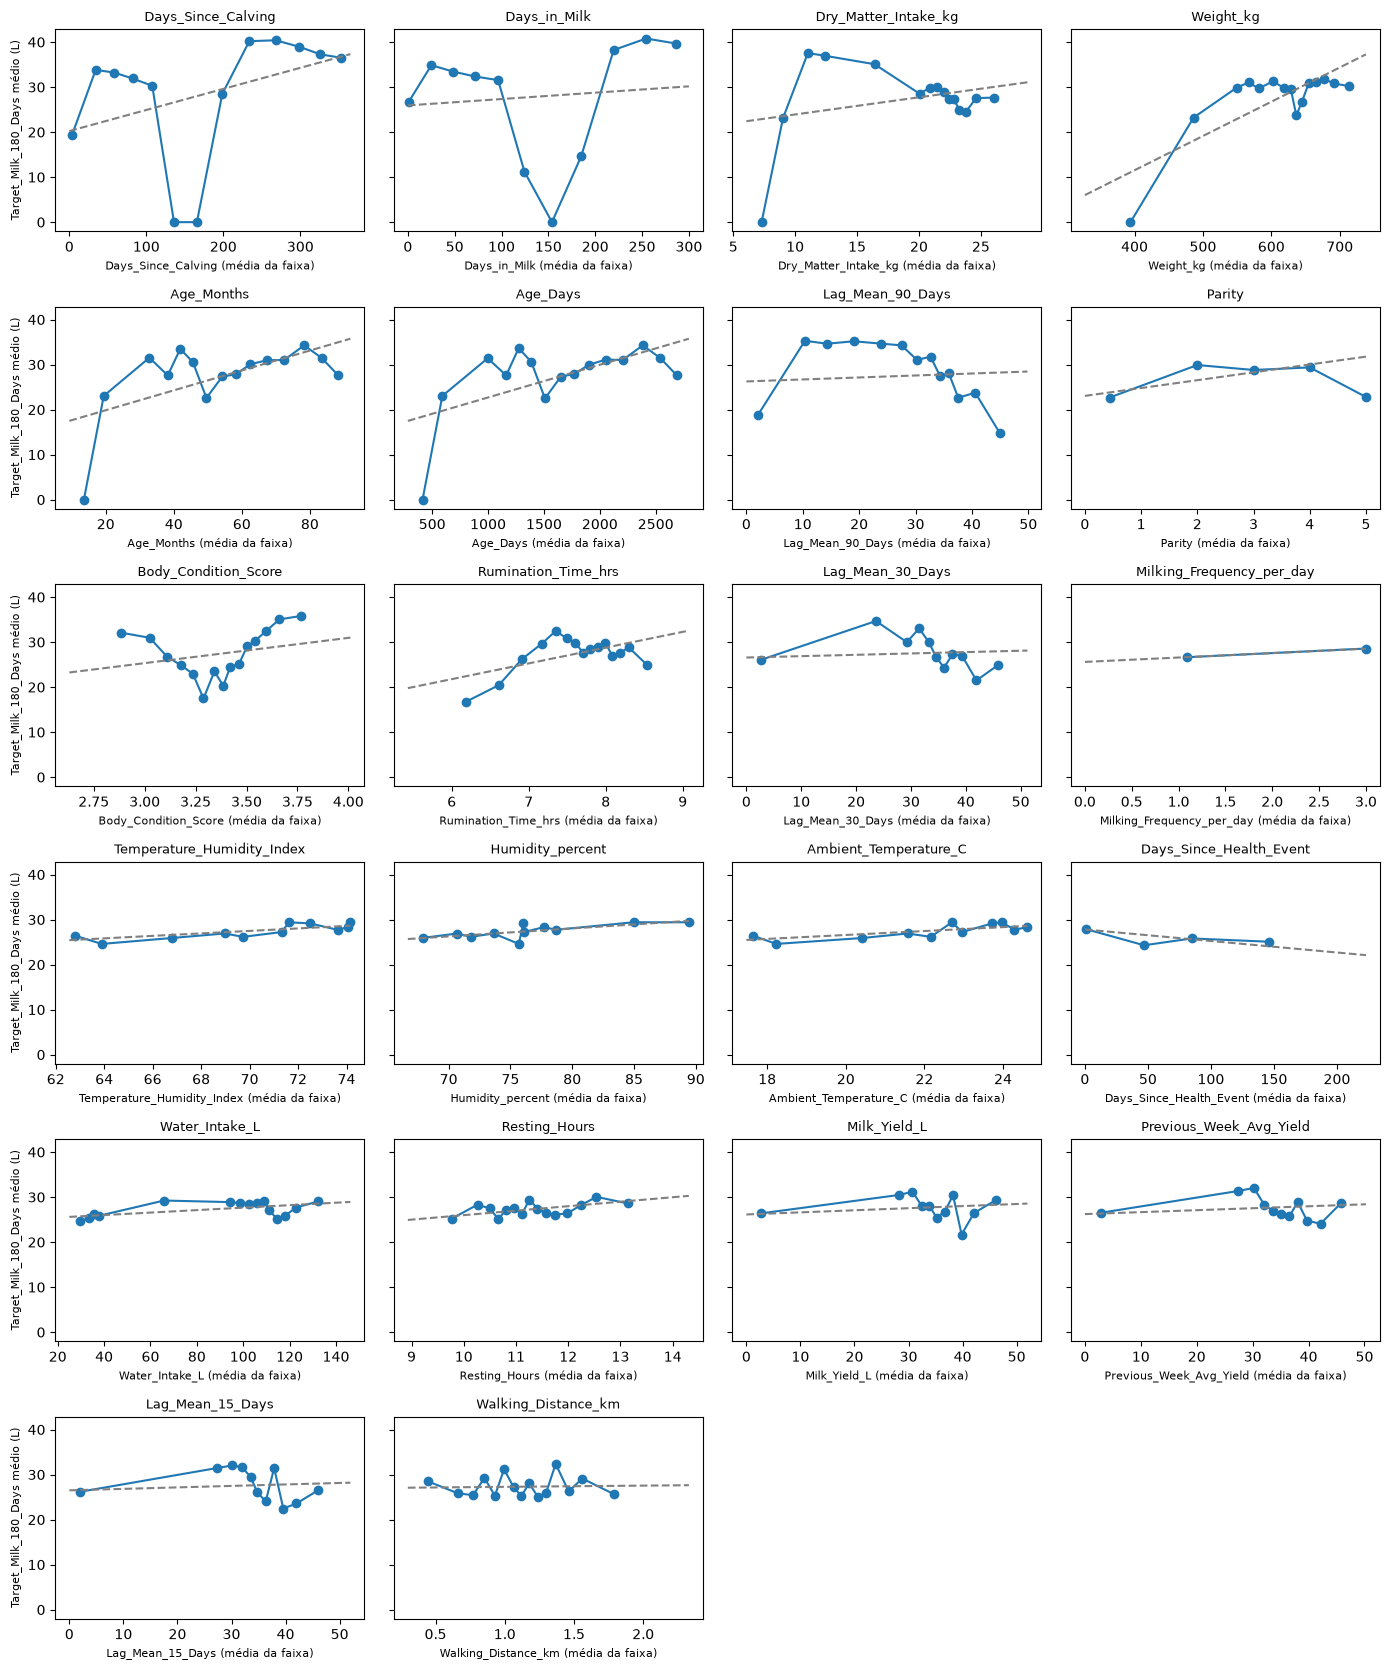

In [22]:
#====================================================================================
#=========================== GRÁFICOS DE MÉDIA POR FAIXA ============================
#====================================================================================

def plot_faixas(ax, col, n=15):
    dados  = df_train[[col, TARGET]].dropna()
    faixas = pd.qcut(dados[col], q=n, duplicates='drop')
    medias = dados.groupby(faixas, observed=True).mean()
    b, a   = np.polyfit(dados[col], dados[TARGET], 1)
    xs     = np.array([dados[col].min(), dados[col].max()])

    ax.plot(medias[col], medias[TARGET], marker='o')
    ax.plot(xs, a + b * xs, linestyle='--', color='gray')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel(f'{col} (média da faixa)', fontsize=8)

cols = tabela['Feature'].tolist()
nlin = ceil(len(cols) / 4)

fig, axes = plt.subplots(nlin, 4, figsize=(14, 2.8 * nlin), sharey=True)
for ax, col in zip(axes.flat, cols):
    plot_faixas(ax, col)

for ax in axes[:, 0]:
    ax.set_ylabel(f'{TARGET} médio (L)', fontsize=8)

for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
    
plt.tight_layout()
plt.show()




<Axes: xlabel='Days_Since_Calving', ylabel='Milk_Yield_L'>

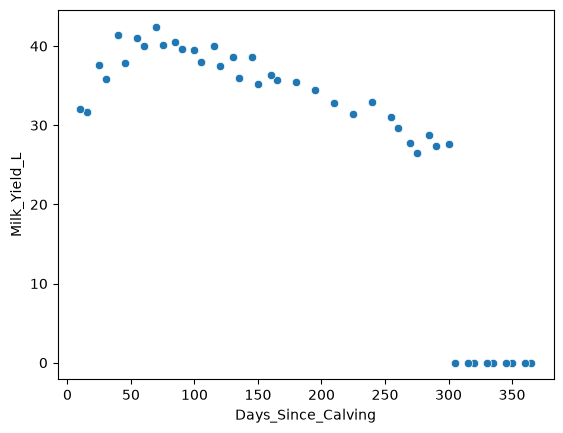

In [23]:
#testando curva de lactação em uma vaca
vaca_prod_dim = df1.loc[(df1['Cattle_ID'] == 'CATTLE_001'), ['Days_Since_Calving', 'Milk_Yield_L']]

sns.scatterplot(vaca_prod_dim, x='Days_Since_Calving', y='Milk_Yield_L')

<Axes: xlabel='Days_Since_Calving', ylabel='Milk_Yield_L'>

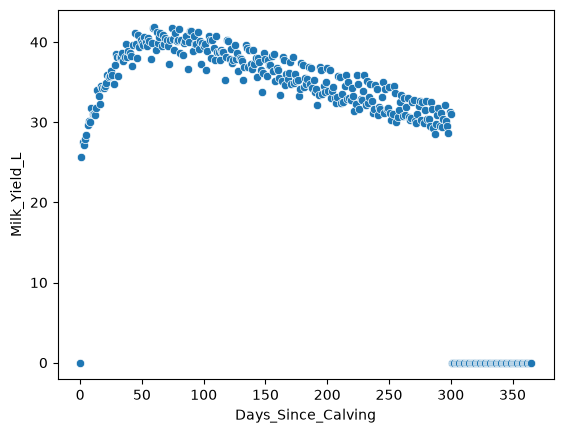

In [24]:
#testando curva de lactação por agrupamento

vaca_agrup_prod_dim = df1.groupby('Days_Since_Calving')['Milk_Yield_L'].mean()

sns.scatterplot(vaca_agrup_prod_dim)

# Resultados

## A tabela

| Feature | Spearman ρ | R² Linear | R² Árvore | Mutual Info | % Outliers | Força | Formato |
|---|---|---|---|---|---|---|---|
| Days_Since_Calving | 0,419 | 0,125 | **0,771** | 0,628 | 0,0 | 🟢 Forte | Curva |
| Days_in_Milk | 0,109 | 0,008 | **0,591** | 0,495 | 0,0 | 🟢 Forte | Curva |
| Dry_Matter_Intake_kg | 0,045 | 0,021 | 0,320 | 0,378 | 0,0 | 🟢 Forte | Curva |
| Weight_kg | 0,212 | 0,156 | 0,256 | 0,270 | 6,0 | 🟢 Forte | Curva |
| Age_Months | 0,235 | 0,093 | 0,244 | 0,333 | 0,0 | 🟡 Moderada | Curva |
| Age_Days | 0,235 | 0,093 | 0,241 | 0,331 | 0,0 | 🟡 Moderada | Curva |
| Lag_Mean_90_Days | 0,069 | 0,002 | 0,191 | 0,368 | 0,0 | 🟡 Moderada | Curva |
| Parity | 0,053 | 0,025 | 0,161 | 0,140 | 19,9 | 🟡 Moderada | Curva |
| Body_Condition_Score | 0,270 | 0,007 | 0,076 | 0,135 | 0,1 | 🔴 Fraca | Sem relação |
| Rumination_Time_hrs | 0,044 | 0,020 | 0,039 | 0,039 | 1,1 | 🔴 Fraca | Sem relação |
| Milk_Yield_L | −0,019 | 0,003 | −0,038 | 0,239 | 0,0 | 🔴 Fraca | Sem relação |
| Temperature_Humidity_Index | 0,109 | 0,005 | −0,012 | 0,000 | 0,0 | 🔴 Fraca | Sem relação |
| Days_Since_Health_Event | −0,086 | 0,005 | −0,010 | 0,000 | 24,5 | 🔴 Fraca | Sem relação |

As outras 9 features (`Lag_Mean_30_Days`, `Lag_Mean_15_Days`, `Previous_Week_Avg_Yield`, `Milking_Frequency_per_day`, `Humidity_percent`, `Ambient_Temperature_C`, `Water_Intake_L`, `Resting_Hours`, `Walking_Distance_km`) também saíram **Fraca / Sem relação**, com R² Máx abaixo de 0,02.

**Leitura geral:** nenhuma feature relevante é reta. Todas as 8 com alguma força são **curvas**, e a reta sozinha nunca explica mais que 16% (Weight_kg).

## O que os gráficos mostram

### 1. O ciclo da vaca: Days_Since_Calving e Days_in_Milk

Os dois gráficos do topo têm o mesmo desenho: o alvo começa médio, **cai até zero** e **volta a subir** até ~40 L. A reta cinza passa no meio e não captura nada disso. Por isso o R² Linear é 0,13 e 0,01, enquanto a árvore chega a 0,77 e 0,59.

A causa é o ciclo produtivo. O intervalo entre partos é de 365 dias (~290 de lactação e ~60 seca), e o alvo é a produção **no dia, 180 dias à frente**:

| Hoje: dias desde o parto | Daqui a 180 dias | Produção no alvo |
|---|---|---|
| 0 (recém-parida) | 180 dias de lactação | média |
| 150 | 330 → **seca** | **zero** |
| 220 | 400 → novo parto, 35 dias de lactação | **alta** (perto do pico) |

O vale em zero do gráfico (entre ~130 e ~170 dias) são exatamente as vacas que estarão secas daqui a 180 dias.

### 2. Weight, Dry_Matter_Intake e Age: a força vem quase toda da primeira faixa

Com o eixo Y igual para todos, fica visível algo que a tabela não mostra: nesses quatro gráficos, **a primeira faixa está em zero** (animais mais leves, mais novos e que comem menos), e a partir da segunda faixa a curva fica **quase plana**, em torno de 25 a 35 L.

Ou seja, essas features separam principalmente **um grupo** de animais (provavelmente os que ainda não estão em lactação ou estão secos) do restante. Entre as vacas adultas, peso e idade quase não mudam o alvo. Vale conferir no notebook quem são os animais dessa primeira faixa antes de interpretar essas features como "quanto mais pesada, mais leite".

### 3. Lag_Mean_90_Days: produção passada alta → produção futura menor

O gráfico mostra um platô em ~35 L e uma **queda** nas faixas mais altas. Vacas que produziram muito nos últimos 90 dias estão perto do pico agora, e daqui a 180 dias estarão no fim da lactação ou secas. É o mesmo ciclo visto de outro ângulo.

### 4. Body_Condition_Score: um U visível, mas fraco

O gráfico mostra um U claro: o alvo é mais baixo para ECC perto de 3,3. Mesmo assim, o R² da árvore é só 0,076. As **médias** das faixas variam, mas dentro de cada faixa as vacas variam muito mais (de 0 a 50 L, por causa do ciclo), então o ECC explica pouco da variação total.

O ECC muda ao longo da lactação (a vaca perde condição no início e recupera no fim), então esse U provavelmente reflete a fase do ciclo, informação que `Days_in_Milk` já traz. É candidata a testar no modelo, sem expectativa alta.

### 5. As fracas de verdade

Clima (THI, temperatura, umidade), água, descanso e caminhada aparecem como **linhas planas** entre 25 e 30 L. A reta, a árvore e a Mutual Information concordam (todas ≈ 0). Isso é coerente com um dataset sintético em que a produção é gerada principalmente pelo ciclo de lactação.

> **Quando a Mutual Information discorda.** `Milk_Yield_L` (MI = 0,24), os `Lag_Mean_15/30` e `Water_Intake_L` têm MI moderada, mas R² da árvore ≈ 0, e os gráficos não mostram forma consistente, só zigue-zague. A estimativa da MI é ruidosa, principalmente com muitos valores repetidos (como os zeros das vacas secas). Quando a MI aponta algo que nem a árvore nem o gráfico confirmam, a feature fica como "a confirmar no modelo", não como forte.

## Validação por vaca × validação comum

Rodando a mesma árvore com `KFold` comum (embaralhado, sem separar por vaca), as notas saem infladas:

| Feature | R² Árvore (KFold comum) | R² Árvore (GroupKFold por vaca) | Efeito |
|---|---|---|---|
| Days_Since_Calving | 0,782 | 0,771 | quase igual |
| Days_in_Milk | 0,600 | 0,591 | quase igual |
| Weight_kg | 0,272 | 0,256 | pequena queda |
| Age_Months | 0,287 | 0,244 | **Forte → Moderada** |
| Lag_Mean_90_Days | 0,254 | 0,191 | **Forte → Moderada** |

As features de **ciclo** quase não mudam: a relação vale igual para qualquer vaca. As que caem mais (`Age`, `Lag_Mean_90_Days`) são as que ajudam a **reconhecer a vaca**: idade e produção média são quase uma "impressão digital" de cada animal. Com KFold comum, a árvore aproveita esse reconhecimento; com GroupKFold, não. A nota por vaca é a honesta.

## Features redundantes

| Par | Correlação (Spearman) | Decisão sugerida |
|---|---|---|
| Age_Days × Age_Months | 1,000 | Mesma informação em unidades diferentes. Manter uma |
| Previous_Week_Avg_Yield × Milk_Yield_L | 0,988 | Quase idênticas. Manter uma |
| Lag_Mean_15_Days × Lag_Mean_30_Days | 0,977 | Manter uma (ou só a de 90 dias, que é a única com força) |
| Ambient_Temperature_C × Temperature_Humidity_Index | 0,972 | Esperado: o THI é calculado a partir da temperatura. Manter uma |
| Water_Intake_L × Milk_Yield_L | 0,956 | O consumo de água acompanha a produção do dia |
| Previous_Week_Avg_Yield × Lag_Mean_15_Days | 0,950 | Mais um par de medidas de produção recente |

Redundância não atrapalha um modelo de árvores na previsão, mas divide a importância entre as features do par e deixa a interpretação confusa. Para modelos lineares, atrapalha também a estabilidade dos coeficientes.

## Conclusões e próximos passos

1. **O alvo é governado pelo ciclo de lactação.** `Days_Since_Calving` e `Days_in_Milk` dominam, e a relação é uma curva com vale em zero.
2. **Nenhuma relação relevante é reta.** Isso favorece modelos de árvores (Random Forest, Gradient Boosting), que no backtesting do projeto já tiveram o menor erro. Um modelo linear só funcionaria com features transformadas (por exemplo, a fase da lactação daqui a 180 dias).
3. **Peso, idade e consumo** separam principalmente um grupo de animais (a primeira faixa, com alvo zero). Conferir quem são antes de interpretar.
4. **Remover redundâncias** antes de modelar: uma de cada par da tabela acima.
5. **Próximo passo:** treinar o modelo com todas as features na validação temporal do projeto e medir a **importância por permutação**. É ela, e não esta tabela, que decide o que fica.


### 5.1.3 Análise Univariada Categóricas

In [25]:
# ==================================================================
# PARTE 1 — Análise Univariada: Tabela Resumo + Cache pros gráficos
# ==================================================================


TARGET = 'Target_Milk_180_Days'
GRUPO  = 'Cattle_ID'

cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]
gkf = GroupKFold(n_splits=5)

def r2_cv_categoria(serie, y, grupos):
    prev = pd.Series(np.nan, index=y.index)
    for idx_tr, idx_te in gkf.split(serie, y, grupos):
        medias = y.iloc[idx_tr].groupby(serie.iloc[idx_tr]).mean()
        prev.iloc[idx_te] = serie.iloc[idx_te].map(medias).fillna(y.iloc[idx_tr].mean()).values
    return r2_score(y, prev)



linhas = []
for col in cat_cols:
    serie = df_train[col].fillna('Missing')
    y, g  = df_train[TARGET], df_train[GRUPO]

    medias = y.groupby(serie).mean()
    n      = serie.value_counts()
    eta2   = (n * (medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    r2_cv  = r2_cv_categoria(serie, y, g)

    linhas.append({
        'Feature'          : col,
        'Nº Categorias'    : serie.nunique(),
        '% Menor Categoria': n.min() / len(serie) * 100,
        'η²'               : eta2,
        'R² CV'            : r2_cv,
        'Média por Cat.'   : {k: round(v, 1) for k, v in medias.sort_values(ascending=False).items()},
    })

def forca(r2):
    if r2 >= 0.25:   return '🟢 Forte'
    elif r2 >= 0.09: return '🟡 Moderada'
    else:            return '🔴 Fraca'

tabela_cat = pd.DataFrame(linhas)
tabela_cat['Força'] = tabela_cat['R² CV'].apply(forca)
tabela_cat = tabela_cat.sort_values('R² CV', ascending=False).reset_index(drop=True)

display(tabela_cat.style.format(precision=3).background_gradient(subset=['R² CV'], cmap='Greens'))

/tmp/ipykernel_2684/521756094.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]


,Feature,Nº Categorias,% Menor Categoria,η²,R² CV,Média por Cat.,Força
0,Lactation_Stage,5,13.667,0.439,0.425,"{'Dry': 37.2, 'Late': 36.7, 'Early': 34.4, 'Mid': 16.9, 'Pre_Lactation': 12.1}",🟢 Forte
1,Animal_Category,2,13.667,0.149,0.137,"{'Cow': 29.7, 'Heifer': 12.1}",🟡 Moderada
2,Body_Condition_Class,3,0.083,0.010,0.006,"{'high': 45.4, 'low': 32.2, 'ok': 26.9}",🔴 Fraca
3,Season,3,8.333,0.007,-0.003,"{'Autumn': 28.8, 'Spring': 26.9, 'Winter': 26.1}",🔴 Fraca
4,Heat_Stress_Class,3,33.333,0.005,-0.007,"{'Moderate': 28.7, 'Mild': 27.4, 'No_Stress': 25.8}",🔴 Fraca
5,Health_Status,4,0.250,0.004,-0.008,"{'Metabolic': 35.9, 'Lameness': 31.7, 'Healthy': 27.4, 'Mastitis': 22.2}",🔴 Fraca


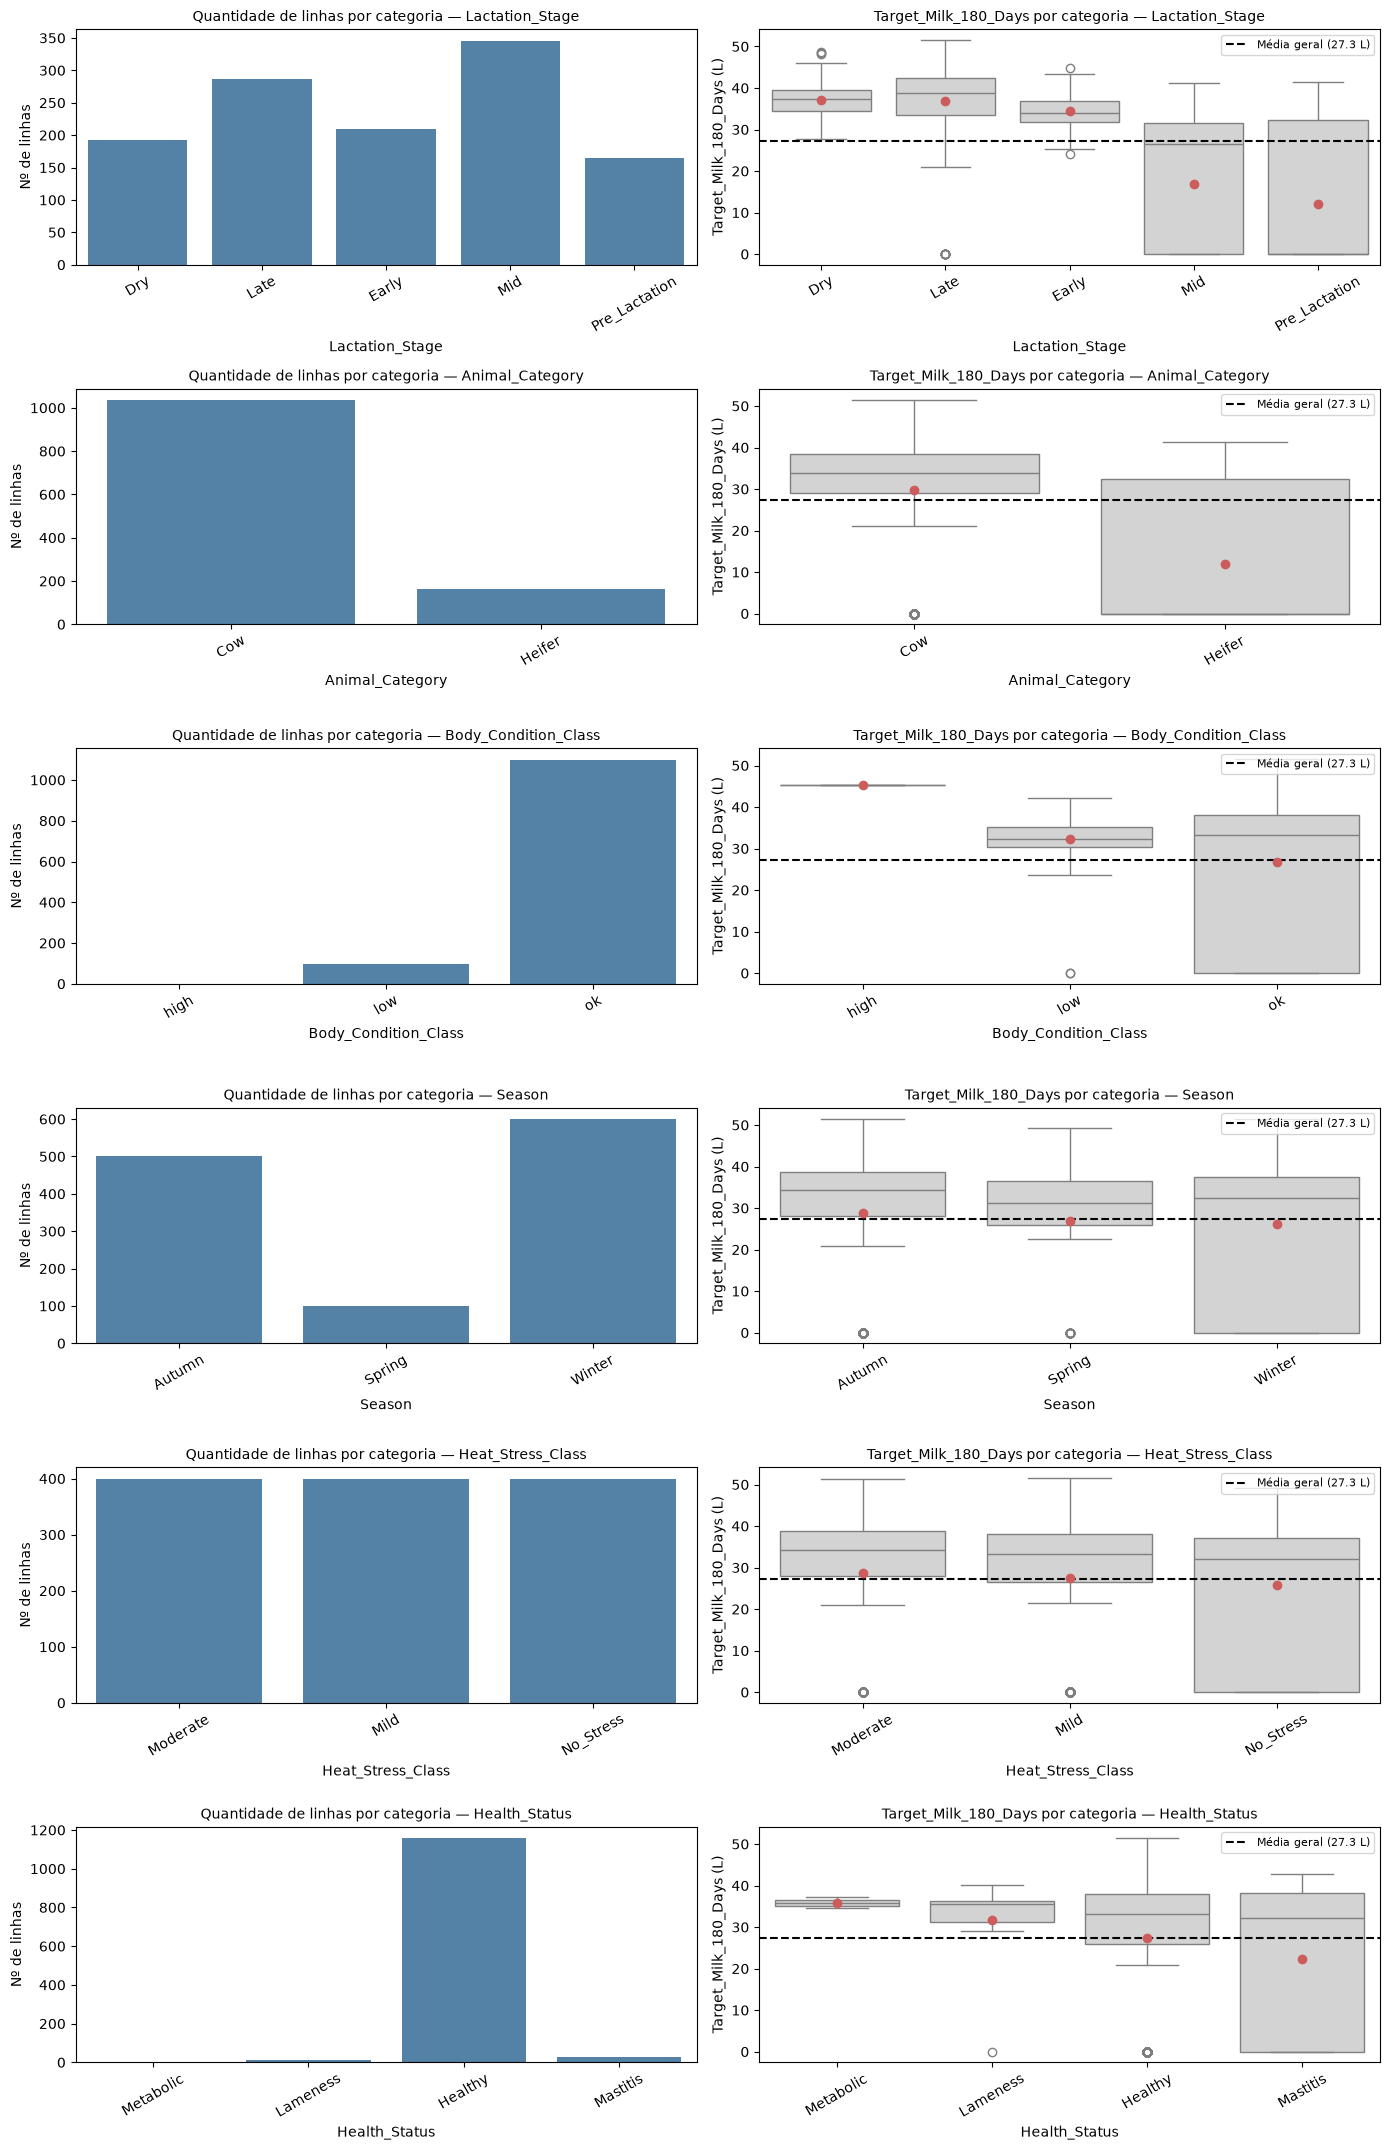

In [26]:
# ======================================================================
# PARTE 2 — Gráficos Detalhados (reaproveitando o que já foi calculado)
# ======================================================================

media_geral = df_train[TARGET].mean()
fig, axes = plt.subplots(len(cat_cols), 2, figsize=(14, 3.6 * len(cat_cols)))

for (ax1, ax2), col in zip(axes, tabela_cat['Feature']):
    serie = df_train[col].fillna('Missing')
    ordem = df_train[TARGET].groupby(serie).mean().sort_values(ascending=False).index

    sns.countplot(x=serie, order=ordem, ax=ax1, color='steelblue')
    ax1.set_title(f'Quantidade de linhas por categoria — {col}', fontsize=10)
    ax1.set_xlabel(col)
    ax1.set_ylabel('Nº de linhas')
    ax1.tick_params(axis='x', rotation=30)

    sns.boxplot(x=serie, y=df_train[TARGET], order=ordem, ax=ax2, color='lightgray', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='indianred', markeredgecolor='indianred'))
    ax2.axhline(media_geral, color='black', linestyle='--', label=f'Média geral ({media_geral:.1f} L)')
    ax2.set_title(f'{TARGET} por categoria — {col}', fontsize=10)
    ax2.set_xlabel(col)
    ax2.set_ylabel(f'{TARGET} (L)')
    ax2.tick_params(axis='x', rotation=30)
    ax2.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

# Análise Univariada Categórica para Regressão — Explicação do Código

## Bloco 1 — Configuração e função do R² validado

### Configuração

```python
import seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

TARGET = 'Target_Milk_180_Days'
GRUPO  = 'Cattle_ID'

cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]
gkf = GroupKFold(n_splits=5)
```

- **`TARGET`**: a coluna que se quer prever.
- **`GRUPO`**: a coluna que identifica cada vaca. Usada para separar treino e teste por animal.
- **`cat_cols`**: as colunas de texto (categóricas), **sem o `Cattle_ID`**. Ele é o ID da vaca: serve para agrupar a validação, não como feature.
- **`gkf`**: `GroupKFold` com 5 partes. Garante que **todas as linhas de uma vaca fiquem na mesma parte**, para o teste ser sempre em vacas que o modelo não viu.

### A ideia da função

A função `r2_cv_categoria` responde: **"se eu previsse o leite só pela categoria, quanto eu acertaria numa vaca que nunca vi?"**

O "modelo" é o mais simples possível: aprende a **média do alvo em cada categoria** (ex.: vacas Dry produzem 37 L em média) e, para prever uma linha nova, usa a média da categoria daquela linha. As médias são aprendidas com um grupo de vacas e testadas em **outras** vacas. É a mesma lógica do `cross_val_score` da análise numérica, escrita à mão porque o sklearn não tem um modelo pronto de "média por categoria".

### Assinatura da função

```python
def r2_cv_categoria(serie, y, grupos):
```

- **`serie`**: a coluna categórica (ex.: `Lactation_Stage`).
- **`y`**: o alvo (`Target_Milk_180_Days`).
- **`grupos`**: o ID da vaca (`Cattle_ID`).

### A "folha em branco" das previsões

```python
    prev = pd.Series(np.nan, index=y.index)
```

- **`pd.Series(np.nan, ...)`**: cria uma coluna toda vazia (NaN), uma posição para cada linha do dataset.
- **`index=y.index`**: o mesmo índice do alvo, para cada previsão ficar alinhada com o valor real da mesma linha.

Ao final do loop, essa coluna estará **toda preenchida**: cada linha cai no teste **exatamente uma vez** entre as 5 rodadas, e é nessa rodada que recebe a sua previsão.

### O loop das 5 rodadas

```python
    for idx_tr, idx_te in gkf.split(serie, y, grupos):
```

- **`gkf.split(...)`**: divide as vacas em 5 grupos. A cada rodada, 1 grupo vira **teste** e os outros 4 viram **treino**.
- **`idx_tr`, `idx_te`**: as **posições** (0, 1, 2…) das linhas de treino e de teste daquela rodada. São posições, não rótulos do índice, por isso o código usa `.iloc` em seguida.
- **`serie, y`**: o `split` só usa os dois para saber quantas linhas existem. Quem decide a divisão é o `grupos`.

### Aprender as médias (só no treino)

```python
        medias = y.iloc[idx_tr].groupby(serie.iloc[idx_tr]).mean()
```

- **`y.iloc[idx_tr]`**: o alvo só das linhas de treino.
- **`serie.iloc[idx_tr]`**: a categoria só das linhas de treino.
- **`.groupby(...).mean()`**: agrupa o alvo pela categoria e tira a média de cada uma. O resultado é uma "tabela de consulta", por exemplo: `Dry → 37,0 | Mid → 10,0 | Early → 30,0`.

As médias **não usam nenhuma linha do teste**. Se usassem, o modelo estaria "colando" na prova.

### Prever as linhas de teste

```python
        prev.iloc[idx_te] = serie.iloc[idx_te].map(medias).fillna(y.iloc[idx_tr].mean()).values
```

- **`serie.iloc[idx_te]`**: a categoria de cada linha de teste.
- **`.map(medias)`**: troca cada categoria pela média dela na tabela de consulta (`Dry` → 37,0). Funciona como um PROCV.
- **`.fillna(y.iloc[idx_tr].mean())`**: se uma categoria do teste **não existir no treino**, o `.map` devolve NaN. Nesse caso, a previsão vira a **média geral do treino**, o chute mais honesto quando não há informação.
- **`.values`**: tira o índice e deixa só os números, para serem gravados **por posição**, sem o pandas tentar casar índices.
- **`prev.iloc[idx_te] = ...`**: grava as previsões nas posições de teste daquela rodada.

### A nota final

```python
    return r2_score(y, prev)
```

- **`r2_score(y, prev)`**: compara o alvo real com as previsões, todas feitas em vacas "nunca vistas". 1 = acerta tudo; 0 = igual a chutar a média geral; negativo = pior que chutar a média geral.

### Exemplo à mão: 3 vacas, 6 linhas (3 rodadas, uma vaca por rodada)

| Linha | Vaca | Estágio | Alvo (L) |
|---|---|---|---|
| 0 | A | Dry | 40 |
| 1 | A | Mid | 0 |
| 2 | B | Dry | 36 |
| 3 | B | Mid | 10 |
| 4 | C | Dry | 38 |
| 5 | C | Early | 30 |

**Rodada 1: teste = vaca A, treino = vacas B e C**

- Médias no treino: Dry = (36 + 38) / 2 = **37**; Mid = **10**; Early = **30**.
- Previsões: linha 0 (Dry) → **37**; linha 1 (Mid) → **10**.

**Rodada 2: teste = vaca B, treino = vacas A e C**

- Médias no treino: Dry = (40 + 38) / 2 = **39**; Mid = **0**; Early = **30**.
- Previsões: linha 2 (Dry) → **39**; linha 3 (Mid) → **0**.

**Rodada 3: teste = vaca C, treino = vacas A e B**

- Médias no treino: Dry = (40 + 36) / 2 = **38**; Mid = (0 + 10) / 2 = **5**. **Não existe Early no treino.**
- Previsões:
    - linha 4 (Dry) → **38**;
    - linha 5 (Early) → o `.map` devolve NaN, e o `fillna` usa a média geral do treino: (40 + 0 + 36 + 10) / 4 = **21,5**.

**Resultado: `prev` toda preenchida**

| Linha | Real | Previsto | Erro² |
|---|---|---|---|
| 0 | 40 | 37 | 9 |
| 1 | 0 | 10 | 100 |
| 2 | 36 | 39 | 9 |
| 3 | 10 | 0 | 100 |
| 4 | 38 | 38 | 0 |
| 5 | 30 | 21,5 | 72,25 |

- SSE (soma dos erros²) = **290,25**
- SST (erro de chutar a média geral, 25,67, para todo mundo) = **1.387,33**
- **R² CV = 1 − 290,25 / 1.387,33 = 0,79**: a categoria explica bem o alvo em vacas que o "modelo" não viu.

> **Pontos que passam despercebidos:**
>
> - A **linha 5** mostra por que o `fillna` existe. Sem ele, a previsão seria NaN e o `r2_score` daria erro. Isso acontece de verdade com categorias raras, como o `high` do `Body_Condition_Class`, que tem uma linha só.
> - Na rodada 2, a média de Mid (**0**) veio de **uma vaca só**. Com poucas linhas, a média de uma categoria oscila muito. É para avisar disso que existe a coluna **% Menor Categoria**.
> - **Por que não usar LabelEncoder + modelo aqui:** o LabelEncoder numera as categorias em ordem alfabética, e um modelo linear leria essa ordem falsa como grandeza. Prever pela média da categoria não numera nada, então não há ordem falsa.

## Bloco 2 — O loop: calcular as métricas de cada feature

```python
linhas = []
for col in cat_cols:
    serie = df_train[col].fillna('Missing')
    y, g  = df_train[TARGET], df_train[GRUPO]

    medias = y.groupby(serie).mean()
    n      = serie.value_counts()
    eta2   = (n * (medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    r2_cv  = r2_cv_categoria(serie, y, g)

    linhas.append({
        'Feature'          : col,
        'Nº Categorias'    : serie.nunique(),
        '% Menor Categoria': n.min() / len(serie) * 100,
        'η²'               : eta2,
        'R² CV'            : r2_cv,
        'Média por Cat.'   : {k: round(v, 1) for k, v in medias.sort_values(ascending=False).items()},
    })
```

- **`linhas = []`**: lista vazia que recebe um dicionário (uma linha da tabela) por feature.
- **`serie`**: a feature com faltantes virando a categoria `'Missing'`. É usada **em todos os cálculos**, para nenhuma categoria sumir de um lugar e aparecer em outro.
- **`y, g`**: o alvo e o ID da vaca.
- **`medias`**: a média do alvo em cada categoria, usando **todas** as linhas.
- **`n`**: quantas linhas cada categoria tem.
- **`eta2` (η², "eta ao quadrado")**: explicado em detalhe abaixo.
- **`r2_cv`**: chama a função do Bloco 1. É o R² validado em vacas não vistas. **É ele que decide a força.**
- **`Nº Categorias`**: quantas categorias diferentes a feature tem.
- **`% Menor Categoria`**: o tamanho da categoria mais rara, em porcentagem. Mostra se há categoria pequena demais para confiar na média dela.
- **`Média por Cat.`**: as médias do alvo por categoria, da maior para a menor, arredondadas em 1 casa. O `{k: ... for k, v in ...items()}` monta um dicionário `categoria → média`.

### O que é o η²

O η² vem da **ANOVA** e responde: **"que fração da variação do alvo é explicada pelas diferenças entre as categorias?"** Na prática, é o **R² de prever cada linha pela média da sua categoria**, calculado nos próprios dados, sem separar treino e teste. Faz o papel que o **Cramér's V** fazia na classificação.

- **0**: todas as categorias têm a mesma média, então a categoria não diz nada sobre o alvo.
- **1**: dentro de cada categoria todas as linhas têm o mesmo valor, então saber a categoria é saber o alvo.

```
η² = variação ENTRE as categorias / variação TOTAL
```

- **Numerador, `(n * (medias - y.mean()) ** 2).sum()`**: o quanto a média de cada categoria se afasta da média geral, ao quadrado e **pesado pelo tamanho** (`n`) da categoria.
- **Denominador, `((y - y.mean()) ** 2).sum()`**: o quanto cada linha se afasta da média geral, ao quadrado. É a variação total do alvo, o mesmo SST do R².

**Exemplo com as mesmas 6 linhas do Bloco 1** (média geral = 154 / 6 = **25,67**):

| Categoria | n | Média | (média − 25,67)² | × n |
|---|---|---|---|---|
| Dry | 3 | (40 + 36 + 38) / 3 = 38 | 152,11 | 456,33 |
| Mid | 2 | (0 + 10) / 2 = 5 | 427,11 | 854,22 |
| Early | 1 | 30 | 18,78 | 18,78 |
| | | | **Soma (entre)** | **1.329,33** |

- Variação total (SST) = **1.387,33**
- **η² = 1.329,33 / 1.387,33 = 0,958**

### Por que o η² (0,958) deu maior que o R² CV (0,79)?

| | Médias calculadas com… | Resultado |
|---|---|---|
| **η²** | **todas** as linhas, inclusive a que está sendo "prevista" | 0,958 |
| **R² CV** | só as **outras vacas** (treino) | 0,79 |

No η², a linha 5 (Early, 30 L) é a **única** Early, então a média de Early é ela mesma: "prevê" 30 e acerta em cheio. No R² CV, ela não existia no treino e recebeu o chute de 21,5. É como corrigir uma prova com o gabarito que o próprio aluno escreveu: a nota sai alta, mas não prova nada.

- **η² ≈ R² CV**: a relação é sólida e vale para vacas novas (ex.: `Lactation_Stage`, 0,439 contra 0,425).
- **η² bem maior que R² CV**: parte da nota vem de "decorar" categorias pequenas e não se repete em dados novos.

> **Pontos que passam despercebidos:**
>
> - O η² **sempre** sobe com mais categorias, mesmo que sejam aleatórias. No caso extremo, com uma categoria por linha, o η² seria 1. O R² CV não cai nessa.
> - `n` vem de `value_counts()` (ordenado da maior para a menor contagem) e `medias` vem de `groupby` (ordem alfabética), então as duas estão em **ordens diferentes**. A conta `n * (medias - ...)` funciona mesmo assim porque o pandas **alinha pelo índice** (o nome da categoria), não pela posição. Se você convertesse as duas para listas ou arrays, a conta multiplicaria a contagem de uma categoria pela média de outra, sem dar erro nenhum.

## Bloco 3 — Montar a tabela e classificar

```python
def forca(r2):
    if r2 >= 0.25:   return '🟢 Forte'
    elif r2 >= 0.09: return '🟡 Moderada'
    else:            return '🔴 Fraca'

tabela_cat = pd.DataFrame(linhas)
tabela_cat['Força'] = tabela_cat['R² CV'].apply(forca)
tabela_cat = tabela_cat.sort_values('R² CV', ascending=False).reset_index(drop=True)

display(tabela_cat.style.format(precision=3).background_gradient(subset=['R² CV'], cmap='Greens'))
```

- **`forca(r2)`**: classifica pelo R² CV, com os mesmos cortes da análise numérica (0,25 e 0,09), para as duas tabelas serem comparáveis.
- **`pd.DataFrame(linhas)`**: transforma a lista de dicionários numa tabela, um dicionário por linha.
- **`.apply(forca)`**: aplica a função a cada valor da coluna R² CV.
- **`sort_values(...).reset_index(drop=True)`**: ordena da relação mais forte para a mais fraca e renumera o índice de 0 em diante.
- **`.style.format(precision=3)`**: mostra os números com 3 casas decimais.
- **`.background_gradient(subset=['R² CV'], cmap='Greens')`**: pinta só a coluna R² CV, do claro (fraca) ao escuro (forte).
- **Sem coluna "Formato"**: categórica não tem "reta ou curva", porque as categorias não têm ordem.

## Bloco 4 — Gráficos por categoria

```python
media_geral = df_train[TARGET].mean()
fig, axes = plt.subplots(len(cat_cols), 2, figsize=(14, 3.6 * len(cat_cols)))

for (ax1, ax2), col in zip(axes, tabela_cat['Feature']):
    serie = df_train[col].fillna('Missing')
    ordem = df_train[TARGET].groupby(serie).mean().sort_values(ascending=False).index

    sns.countplot(x=serie, order=ordem, ax=ax1, color='steelblue')
    ax1.set_title(f'Quantidade de linhas por categoria — {col}', fontsize=10)
    ax1.set_xlabel(col)
    ax1.set_ylabel('Nº de linhas')
    ax1.tick_params(axis='x', rotation=30)

    sns.boxplot(x=serie, y=df_train[TARGET], order=ordem, ax=ax2, color='lightgray', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='indianred', markeredgecolor='indianred'))
    ax2.axhline(media_geral, color='black', linestyle='--', label=f'Média geral ({media_geral:.1f} L)')
    ax2.set_title(f'{TARGET} por categoria — {col}', fontsize=10)
    ax2.set_xlabel(col)
    ax2.set_ylabel(f'{TARGET} (L)')
    ax2.tick_params(axis='x', rotation=30)
    ax2.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()
```

- **`media_geral`**: a média do alvo em todo o `df_train`, desenhada como linha de referência.
- **`plt.subplots(len(cat_cols), 2, ...)`**: uma grade com uma linha por feature e 2 gráficos por linha. A altura (`3.6 * len(cat_cols)`) cresce com o número de features.
- **`zip(axes, tabela_cat['Feature'])`**: cada linha da grade (`ax1`, `ax2`) recebe uma feature, na ordem da tabela (mais forte primeiro).
- **`ordem`**: as categorias da maior para a menor média do alvo, a mesma ordem nos dois gráficos.
- **Gráfico 1, `countplot`**: quantas linhas cada categoria tem. Uma categoria com 1 linha tem uma média sem valor.
- **Gráfico 2, `boxplot`**: a distribuição do alvo em cada categoria.
    - A caixa vai do Q1 ao Q3, e a linha dentro dela é a **mediana**.
    - **`showmeans=True` + `meanprops`**: marca a **média** com um ponto vermelho.
    - **`axhline(media_geral)`**: a linha tracejada é a média geral.
- **`tick_params(axis='x', rotation=30)`**: inclina os nomes das categorias para não se sobreporem.
- **Um loop só, sem `cache`**: os gráficos usam direto o que precisam.

> **Como ler cada gráfico.** Pontos vermelhos em alturas bem diferentes = feature que separa o alvo. Pontos todos perto da linha tracejada = sem relação. Caixa muito alta (de 0 a 40 L) = categoria que mistura vacas em situações diferentes. Antes de confiar numa média, olhe o countplot: categoria com poucas linhas engana.


## 5.2 Análise Variável Bivariada

### 5.2.1 Análise Variável Bivariada Numérica

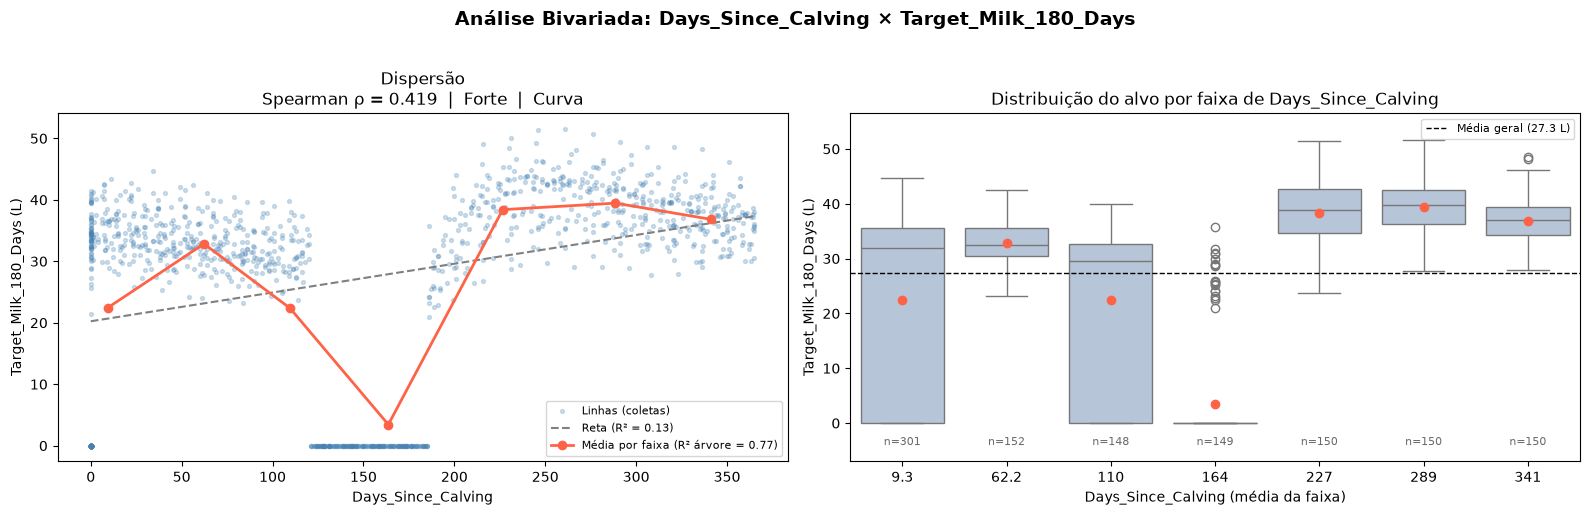

──────────────────────────────────────────────────────────────────────
  Days_Since_Calving
  ρ=0.419  |  R² Linear=0.125  |  R² Árvore=0.771  |  🟢 Forte  |  Curva
──────────────────────────────────────────────────────────────────────



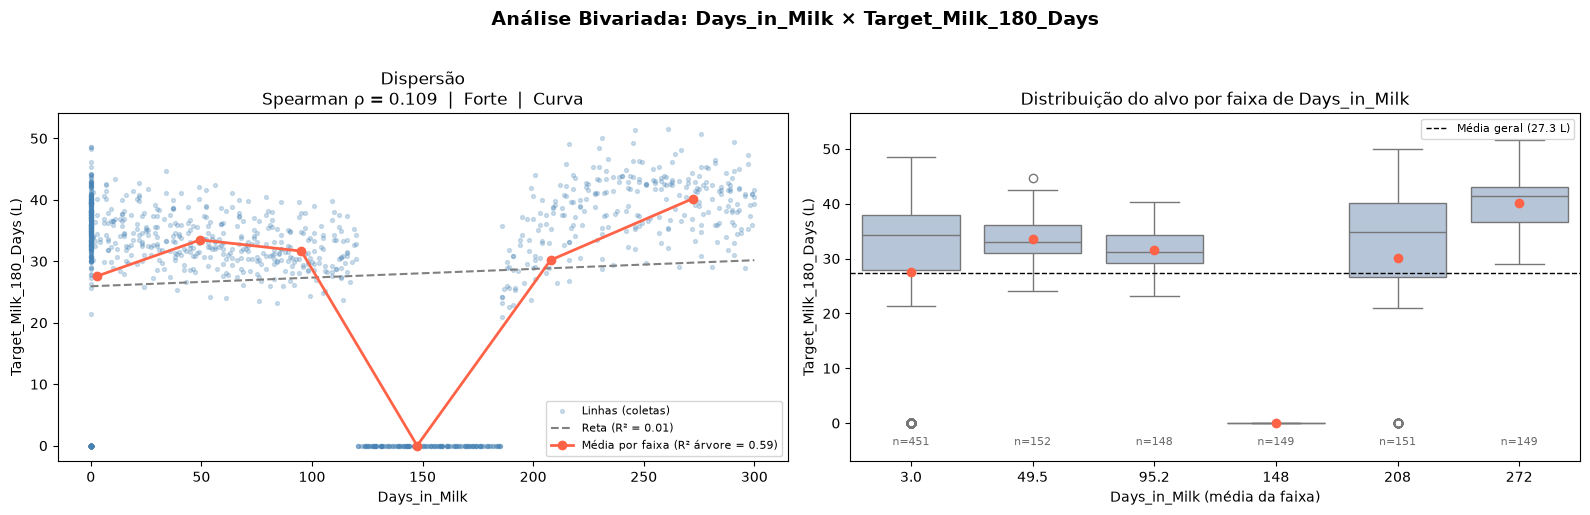

──────────────────────────────────────────────────────────────────────
  Days_in_Milk
  ρ=0.109  |  R² Linear=0.008  |  R² Árvore=0.591  |  🟢 Forte  |  Curva
──────────────────────────────────────────────────────────────────────



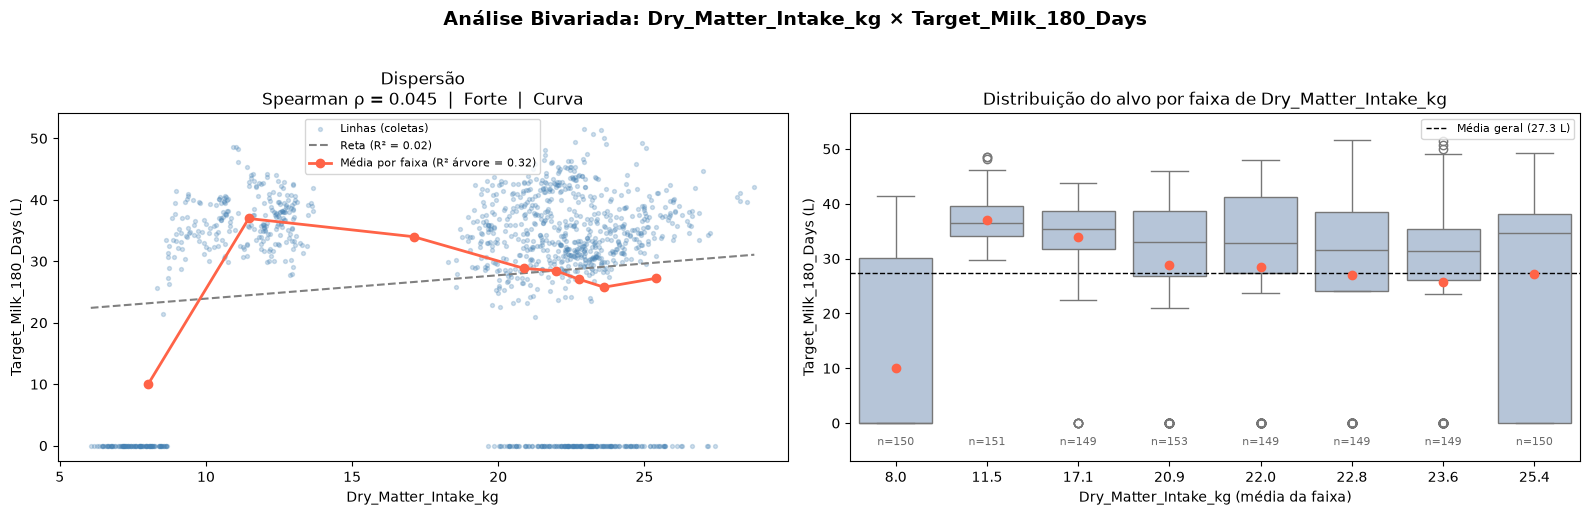

──────────────────────────────────────────────────────────────────────
  Dry_Matter_Intake_kg
  ρ=0.045  |  R² Linear=0.021  |  R² Árvore=0.320  |  🟢 Forte  |  Curva
──────────────────────────────────────────────────────────────────────



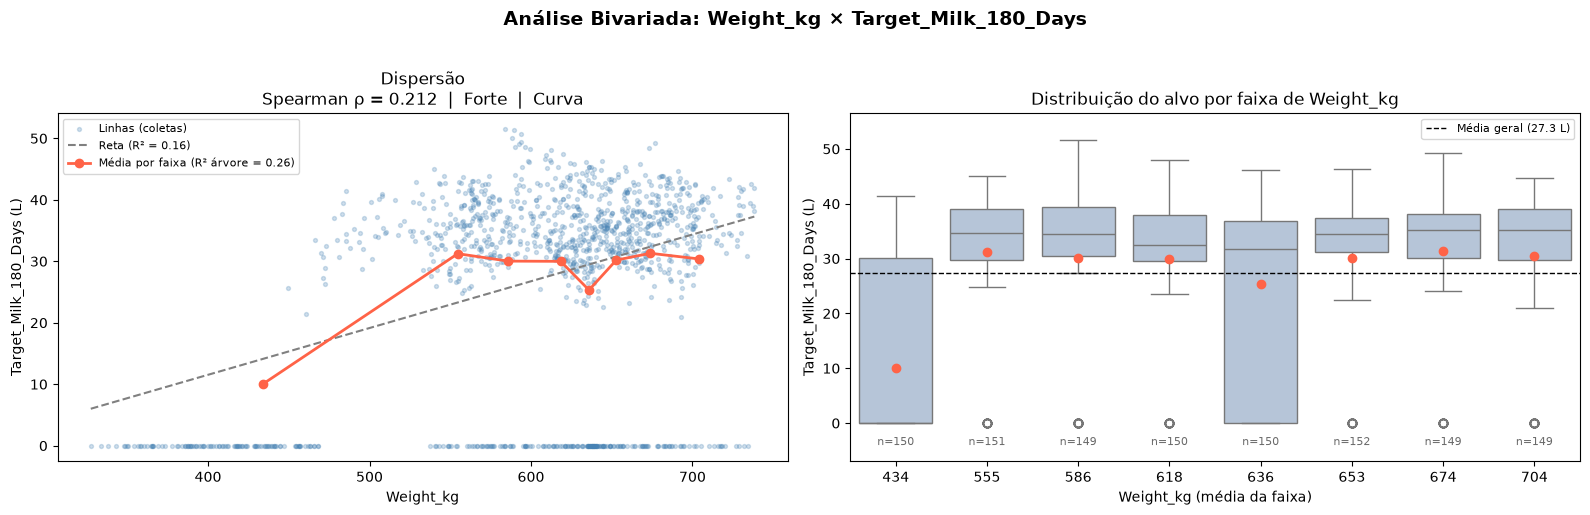

──────────────────────────────────────────────────────────────────────
  Weight_kg
  ρ=0.212  |  R² Linear=0.156  |  R² Árvore=0.256  |  🟢 Forte  |  Curva
──────────────────────────────────────────────────────────────────────



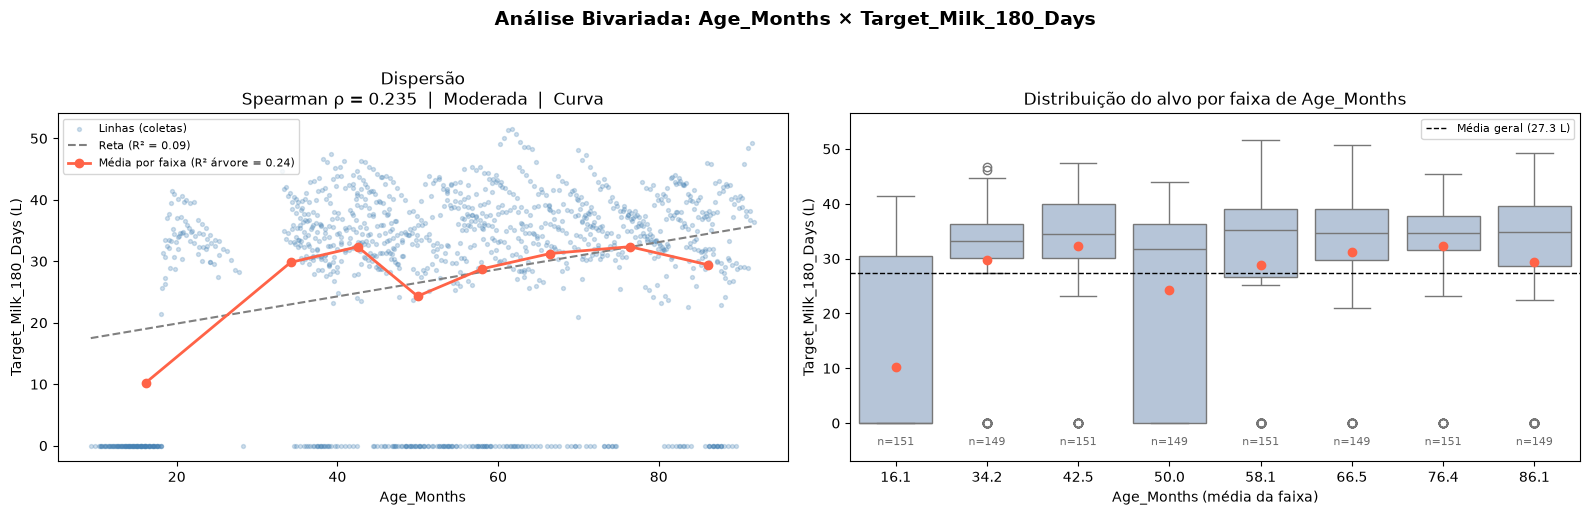

──────────────────────────────────────────────────────────────────────
  Age_Months
  ρ=0.235  |  R² Linear=0.093  |  R² Árvore=0.244  |  🟡 Moderada  |  Curva
──────────────────────────────────────────────────────────────────────



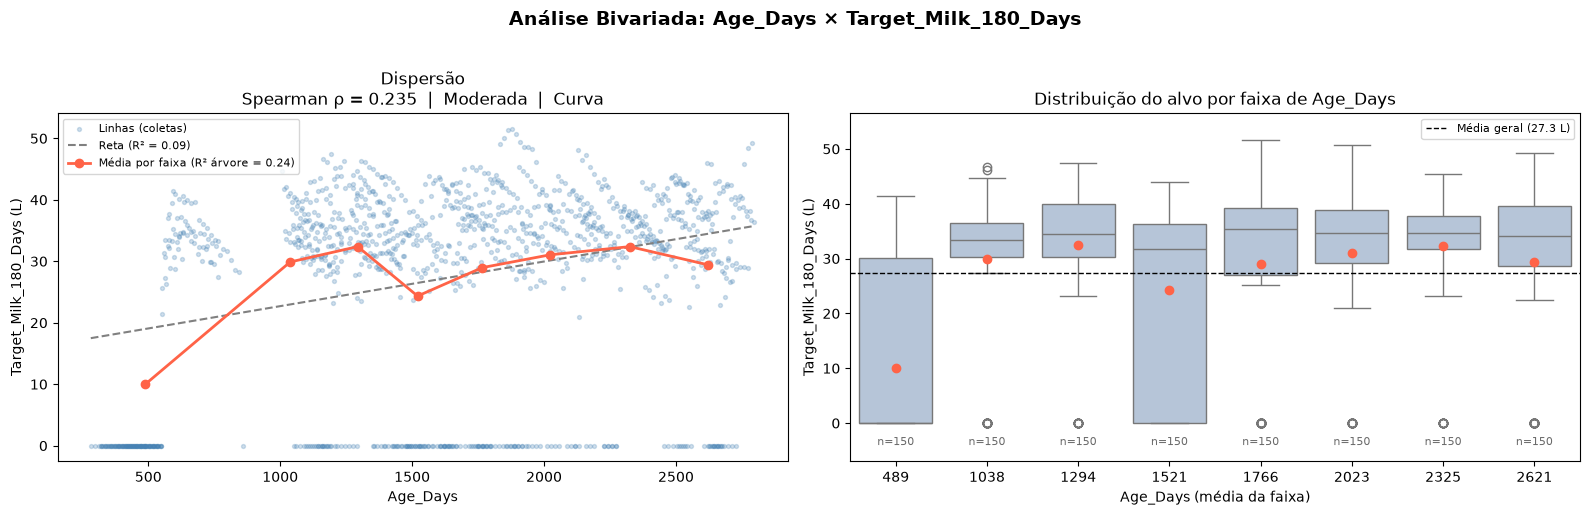

──────────────────────────────────────────────────────────────────────
  Age_Days
  ρ=0.235  |  R² Linear=0.093  |  R² Árvore=0.241  |  🟡 Moderada  |  Curva
──────────────────────────────────────────────────────────────────────



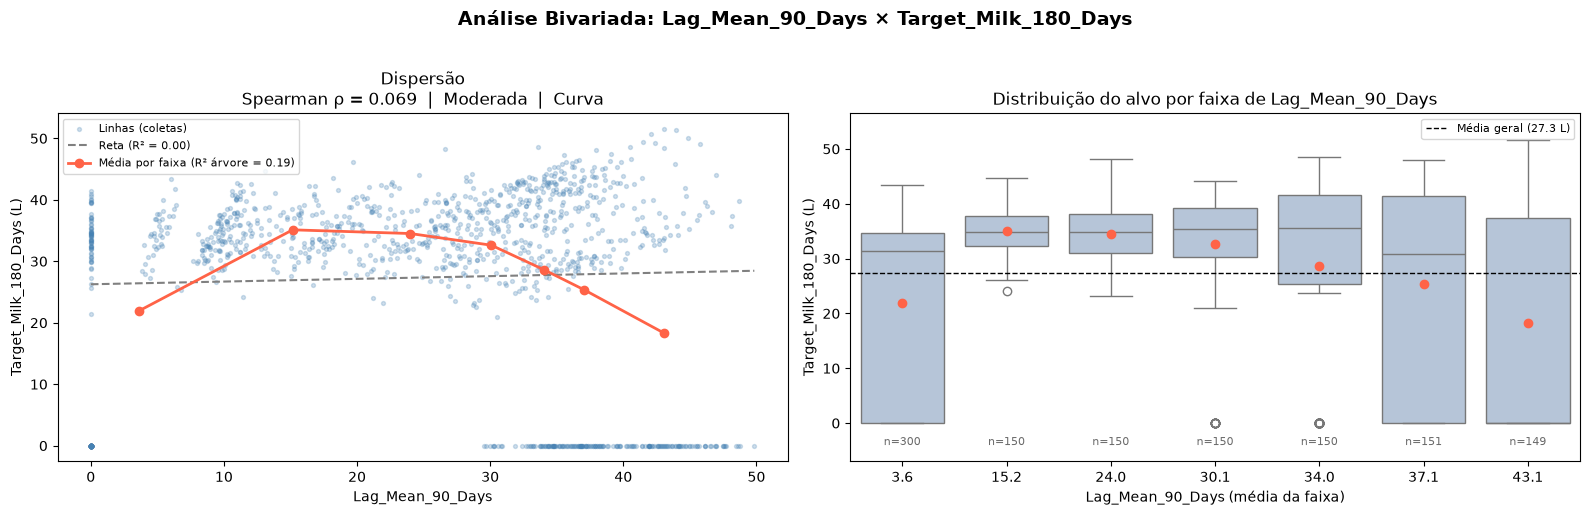

──────────────────────────────────────────────────────────────────────
  Lag_Mean_90_Days
  ρ=0.069  |  R² Linear=0.002  |  R² Árvore=0.191  |  🟡 Moderada  |  Curva
──────────────────────────────────────────────────────────────────────



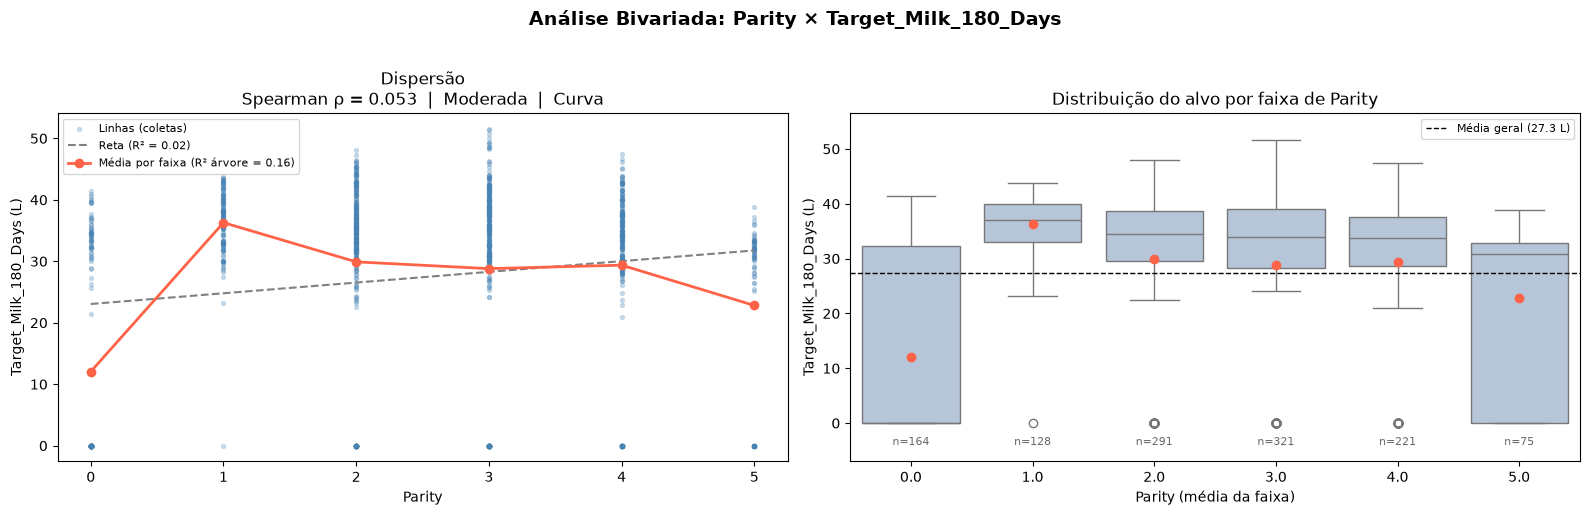

──────────────────────────────────────────────────────────────────────
  Parity
  ρ=0.053  |  R² Linear=0.025  |  R² Árvore=0.161  |  🟡 Moderada  |  Curva
──────────────────────────────────────────────────────────────────────



In [27]:
# ==================================================================
# PARTE 1 — Configuração (reaproveita a tabela da univariada)
# ==================================================================

media_geral  = df_train[TARGET].mean()
cols_detalhe = tabela.loc[tabela['Força'] != '🔴 Fraca', 'Feature'].tolist() #seleciona as colunas fortes/moderadas

for col in cols_detalhe:
    info  = tabela.set_index('Feature').loc[col] #puxa as infos da tabela criada na analise univariada
    dados = df_train[[col, TARGET]].dropna().copy()

    #===================================================================
    # --- Faixas: valores próprios (discreta) ou quantis (contínua) ---
    #===================================================================

    if dados[col].nunique() <= 10:
        dados['faixa'] = dados[col].astype('category') #converte uma coluna object (nomes) para category (0, 1, 3...)
    else:
        dados['faixa'] = pd.qcut(dados[col], q=8, duplicates='drop')

    resumo = (
        dados.groupby('faixa', observed=True)
        .agg(x_medio=(col, 'mean'), alvo_medio=(TARGET, 'mean'), N=(TARGET, 'size'))
    )
    rotulos = [f'{v:.0f}' if abs(v) >= 100 else f'{v:.1f}' for v in resumo['x_medio']]

    #============================================================
    # --- Reta ajustada (o que o R² Linear enxerga) ---
    #============================================================

    b, a = np.polyfit(dados[col], dados[TARGET], 1)
    xs   = np.array([dados[col].min(), dados[col].max()])

    #============================================================
    # --- Plots --- Estrutura
    #============================================================

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {TARGET}',
                 fontsize=14, fontweight='bold', y=1.02)

    #============================================================
    # ── Plot 1: Dispersão + reta + média por faixa ────────────
    #============================================================

    axes[0].scatter(dados[col], dados[TARGET], s=8, alpha=0.25,
                    color='steelblue', label='Linhas (coletas)')
    axes[0].plot(xs, a + b * xs, linestyle='--', color='gray',
                 label=f'Reta (R² = {info["R² Linear"]:.2f})')
    axes[0].plot(resumo['x_medio'], resumo['alvo_medio'], marker='o', color='tomato', lw=2,
                 label=f'Média por faixa (R² árvore = {info["R² Árvore"]:.2f})')

    axes[0].set_title(f'Dispersão\nSpearman ρ = {info["Spearman ρ"]:.3f}  |  '
                      f'{info["Força"][2:]}  |  {info["Formato"]}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel(f'{TARGET} (L)')
    axes[0].legend(fontsize=8)

    #============================================================
    # ── Plot 2: Boxplot do alvo por faixa ────────────
    #============================================================

    sns.boxplot(x=dados['faixa'].cat.codes, y=dados[TARGET], ax=axes[1],
                color='lightsteelblue', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='tomato', markeredgecolor='tomato'))
    axes[1].axhline(media_geral, color='black', linestyle='--', linewidth=1,
                    label=f'Média geral ({media_geral:.1f} L)')

    for i, n in enumerate(resumo['N']):
        axes[1].text(i, -4, f'n={n}', ha='center', fontsize=8, color='dimgray')

    axes[1].set_xticks(range(len(rotulos)))
    axes[1].set_xticklabels(rotulos)
    axes[1].set_ylim(-7, dados[TARGET].max() + 5)
    axes[1].set_title(f'Distribuição do alvo por faixa de {col}')
    axes[1].set_xlabel(f'{col} (média da faixa)')
    axes[1].set_ylabel(f'{TARGET} (L)')
    axes[1].legend(fontsize=8, loc='upper right')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    #============================================================
    # --- Resumo textual ---
    #============================================================

    print(f"{'─'*70}")
    print(f"  {col}")
    print(f"  ρ={info['Spearman ρ']:.3f}  |  R² Linear={info['R² Linear']:.3f}  |  "
          f"R² Árvore={info['R² Árvore']:.3f}  |  {info['Força']}  |  {info['Formato']}")
    print(f"{'─'*70}\n")


# Análise Bivariada Numérica para Regressão — Explicação do Código

A univariada respondeu **quanto** cada feature explica o alvo (a `tabela`). A bivariada abre as features que importam, uma por uma, para ver **como** a relação acontece: onde estão os pontos, onde a reta falha, que grupo de animais cria cada padrão. Por isso ela **não recalcula métricas**: lê tudo da `tabela`.

## PARTE 1 — Configuração

```python
media_geral  = df_train[TARGET].mean()
cols_detalhe = tabela.loc[tabela['Força'] != '🔴 Fraca', 'Feature'].tolist()

for col in cols_detalhe:
    info  = tabela.set_index('Feature').loc[col]
    dados = df_train[[col, TARGET]].dropna().copy()
```

- **`media_geral`**: a média do alvo em todo o `df_train`, usada como linha de referência no boxplot.
- **`cols_detalhe`**: só as features que **não** são Fracas na univariada (8 de 22). As fracas aparecem como linhas planas e já foram vistas na grade de gráficos da univariada.
- **`tabela.set_index('Feature').loc[col]`**: transforma a coluna `Feature` em índice e pega a linha da feature atual. `info['R² Linear']`, `info['Força']` etc. vêm prontos da univariada.
- **`dados`**: a feature e o alvo, sem faltantes. É usado em **todos** os cálculos e gráficos, para todos verem as mesmas linhas.
- **`.copy()`**: cria uma tabela independente. Sem ele, criar a coluna `faixa` em seguida daria o aviso `SettingWithCopyWarning`.

## Faixas: valores próprios (discreta) ou quantis (contínua)

```python
    if dados[col].nunique() <= 10:
        dados['faixa'] = dados[col].astype('category')
    else:
        dados['faixa'] = pd.qcut(dados[col], q=8, duplicates='drop')

    resumo = (
        dados.groupby('faixa', observed=True)
        .agg(x_medio=(col, 'mean'), alvo_medio=(TARGET, 'mean'), N=(TARGET, 'size'))
    )
    rotulos = [f'{v:.0f}' if abs(v) >= 100 else f'{v:.1f}' for v in resumo['x_medio']]
```

- **`nunique() <= 10`**: feature com poucos valores (ex.: `Parity`, de 0 a 5). Cada valor vira a sua própria faixa. Com `qcut`, os valores 0, 1 e 2 cairiam juntos numa faixa só e a diferença entre eles sumiria.
- **`pd.qcut(..., q=8)`**: feature contínua. Divide em 8 faixas com a **mesma quantidade de linhas** cada.
- **`duplicates='drop'`**: se muitos valores forem iguais (ex.: muitos zeros), algumas faixas sairiam repetidas. Esse parâmetro as junta em vez de dar erro.
- **`resumo`**: uma linha por faixa, com três colunas:
    - **`x_medio`**: o valor médio da feature na faixa (posição do ponto no eixo X).
    - **`alvo_medio`**: o leite médio na faixa.
    - **`N`**: quantas linhas caíram na faixa.
- **`.agg(nome=(coluna, função))`**: "agregação nomeada". Cria a coluna `nome` aplicando a `função` à `coluna`, tudo numa chamada só.
- **`rotulos`**: os nomes que aparecem embaixo de cada caixa do boxplot. Valores ≥ 100 sem casa decimal (`434`); menores com uma casa (`22.8`).

## Reta ajustada

```python
    b, a = np.polyfit(dados[col], dados[TARGET], 1)
    xs   = np.array([dados[col].min(), dados[col].max()])
```

- **`np.polyfit(x, y, 1)`**: a melhor reta pelos pontos (grau 1). Devolve primeiro a inclinação (`b`) e depois o intercepto (`a`).
- **`xs`**: só o menor e o maior valor da feature. Para desenhar uma reta bastam dois pontos.

## Plots — Estrutura

```python
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {TARGET}', fontsize=14, fontweight='bold', y=1.02)
```

- **`plt.subplots(1, 2, ...)`**: uma linha com dois gráficos lado a lado (`axes[0]` e `axes[1]`).
- **`suptitle(..., y=1.02)`**: título geral da figura, um pouco acima dos gráficos para não encostar nos títulos individuais.

## Plot 1 — Dispersão + reta + média por faixa

```python
    axes[0].scatter(dados[col], dados[TARGET], s=8, alpha=0.25, color='steelblue', label='Linhas (coletas)')
    axes[0].plot(xs, a + b * xs, linestyle='--', color='gray', label=f'Reta (R² = {info["R² Linear"]:.2f})')
    axes[0].plot(resumo['x_medio'], resumo['alvo_medio'], marker='o', color='tomato', lw=2,
                 label=f'Média por faixa (R² árvore = {info["R² Árvore"]:.2f})')
```

- **`scatter`**: cada ponto azul é **uma coleta** (uma linha do dataset).
    - **`s=8`**: pontos pequenos.
    - **`alpha=0.25`**: transparentes. Onde há muitos pontos sobrepostos, a cor fica mais escura, e dá para ver onde os dados se concentram.
- **Reta cinza tracejada**: `a + b * xs` é a equação da reta. É o que o **R² Linear** enxerga.
- **Linha vermelha**: liga as médias de cada faixa. É o formato real da relação, próximo do que a **árvore** enxerga.
- **`label=...`**: o texto de cada elemento na legenda, já com o R² correspondente.
- **`info["Força"][2:]`** (no título): corta os 2 primeiros caracteres (o emoji e o espaço). O matplotlib não desenha emoji e mostraria um quadrado vazio.

> **Como ler:** linha vermelha colada na cinza = relação **reta**. Linha vermelha fazendo morro, vale ou degrau longe da cinza = **curva**. Pontos azuis formando grupos separados (ex.: uma fileira em zero) = existe um **subgrupo de animais** se comportando diferente.

## Plot 2 — Boxplot do alvo por faixa

```python
    sns.boxplot(x=dados['faixa'].cat.codes, y=dados[TARGET], ax=axes[1], color='lightsteelblue', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='tomato', markeredgecolor='tomato'))
    axes[1].axhline(media_geral, color='black', linestyle='--', linewidth=1, label=f'Média geral ({media_geral:.1f} L)')

    for i, n in enumerate(resumo['N']):
        axes[1].text(i, -4, f'n={n}', ha='center', fontsize=8, color='dimgray')

    axes[1].set_xticks(range(len(rotulos)))
    axes[1].set_xticklabels(rotulos)
    axes[1].set_ylim(-7, dados[TARGET].max() + 5)
```

- **`dados['faixa'].cat.codes`**: o número de cada faixa (0, 1, 2…) em vez do intervalo em texto (`(39.0, 84.0]`), que ficaria ilegível no eixo. Os nomes certos entram depois, com `set_xticklabels`.
- **`boxplot`**: uma caixa por faixa, mostrando a distribuição do leite naquela faixa. A caixa vai do Q1 ao Q3, e a linha dentro dela é a **mediana**.
- **`showmeans=True` + `meanprops`**: marca a **média** com um ponto vermelho, o mesmo valor da linha vermelha do Plot 1.
- **`axhline(media_geral)`**: linha preta tracejada com a média geral. Faixa com o ponto vermelho longe dela = faixa que muda o alvo.
- **`for i, n in enumerate(resumo['N'])`**: escreve `n=...` embaixo de cada caixa, na altura −4. O `enumerate` dá a posição (`i`) e o valor (`n`) ao mesmo tempo.
- **`set_xticks` + `set_xticklabels`**: põe os `rotulos` (valor médio da feature) embaixo de cada caixa.
- **`set_ylim(-7, ...)`**: estende o eixo Y abaixo de zero para os textos `n=...` caberem.

> **Por que o boxplot além da média:** a média esconde se a faixa é homogênea ou uma mistura. Uma caixa que vai de 0 a 35 L com média de 22 L não é "22 L típico": é uma mistura de vacas que estarão secas (0 L) com vacas produzindo bem. O Plot 1 mostra só a média; o Plot 2 mostra essa mistura.

## Fechamento e resumo textual

```python
    plt.tight_layout()
    plt.show()
    plt.close(fig)
```

- **`tight_layout()`**: ajusta os espaços para títulos e rótulos não se sobreporem.
- **`plt.close(fig)`**: libera a figura da memória. Num loop com muitos gráficos, sem isso o matplotlib acumula figuras abertas e avisa.
- **`print(...)`**: uma linha de resumo com as métricas da `tabela`, para quem lê o notebook sem olhar o gráfico.


## Resultados da Análise Bivariada

### Achado principal: as novilhas explicam a força de 4 features

A univariada mostrou que, em `Weight_kg`, `Age_Months` e `Dry_Matter_Intake_kg`, a **primeira faixa** tinha alvo perto de zero e o resto era quase plano, e deixou pendente conferir quem eram esses animais. A bivariada confirma: **são as novilhas**.

| Feature | Primeira faixa | Linhas | Quantas são novilhas (Heifer) | Alvo médio |
|---|---|---|---|---|
| Weight_kg | ≤ 528 kg | 150 | 149 | 10,0 L |
| Age_Months | ≤ 22 meses | 151 | 151 | 10,2 L |
| Dry_Matter_Intake_kg | ≤ 9,8 kg | 150 | 150 | 10,1 L |
| Parity | = 0 | 164 | 164 | 12,1 L |
| Days_Since_Calving | = 0 | 164 | 164 | — |

Ou seja, essas features são fortes porque **identificam a novilha**, não porque "mais peso = mais leite". Entre as vacas adultas, o alvo fica entre 25 e 31 L em todas as faixas de peso, idade e consumo. Na prática, carregam a mesma informação que `Parity = 0`, `Animal_Category = Heifer` e `Lactation_Stage = Pre_Lactation`.

> **Atenção ao `Days_Since_Calving = 0`:** as 164 linhas com valor 0 são **todas novilhas**, que nunca pariram. O 0 aqui não quer dizer "pariu hoje", quer dizer "não se aplica". Para o modelo de árvore isso funciona (ele separa o 0 sozinho), mas a interpretação "0 dias desde o parto" está errada para esses animais.

### Days_Since_Calving: o ciclo, com duas fileiras de zeros

| Dias desde o parto (média da faixa) | 9 | 62 | 110 | **164** | 227 | 289 | 341 |
|---|---|---|---|---|---|---|---|
| Alvo médio (L) | 22,4 | 32,8 | 22,4 | **3,4** | 38,4 | 39,5 | 36,8 |

A dispersão mostra **duas fileiras de pontos em zero**:

- **Em 0 dias**: as novilhas (106 das 164 com alvo zero).
- **Entre ~120 e ~185 dias**: vacas que estarão **secas** daqui a 180 dias.

A primeira e a terceira faixa têm caixas de 0 a ~35 L: misturam vacas que estarão secas com vacas produzindo. Por isso a média delas (22 L) não representa nenhuma vaca real.

### Parity: o 0 e o 1 se destacam

| Parity | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| Alvo médio (L) | **12,1** | **36,3** | 29,9 | 28,8 | 29,4 | 22,8 |
| Linhas | 164 | 128 | 291 | 321 | 221 | 75 |

- **Parity 0**: as novilhas, com caixa de 0 a 32 L. Parte delas ainda não estará em lactação daqui a 180 dias.
- **Parity 1** (1ª lactação): a maior média (36,3 L) e a caixa mais estreita. Isso provavelmente reflete **em que fase do ciclo** as primíparas estavam nos 6 meses do `df_train`, e não que primíparas produzam mais. Não dá para generalizar.
- **Parity 5**: média menor (22,8 L), com caixa descendo até zero. São 75 linhas, então interpretar com cuidado.

### Lag_Mean_90_Days: platô e queda

| Lag 90 dias (L, média da faixa) | 3,6 | 15,2 | 24,0 | 30,1 | 34,0 | 37,1 | 43,1 |
|---|---|---|---|---|---|---|---|
| Alvo médio (L) | 21,9 | 35,1 | 34,5 | 32,6 | 28,7 | 25,3 | **18,3** |

Vacas que produziram muito nos últimos 90 dias estão no pico **agora**, e daqui a 180 dias estarão no fim da lactação ou secas. A primeira faixa (perto de 0 L, 300 linhas) mistura novilhas e vacas que estavam secas.

### Conclusões

1. **Quatro features "fortes" são, na verdade, um detector de novilha.** `Weight_kg`, `Age_Months`/`Age_Days`, `Dry_Matter_Intake_kg` e `Parity = 0` separam o mesmo grupo de 164 linhas. Vale testar no modelo se, com `Lactation_Stage` presente, elas ainda acrescentam alguma coisa.
2. **O ciclo de lactação continua sendo o centro.** `Days_Since_Calving`, `Days_in_Milk` e `Lag_Mean_90_Days` contam a mesma história de ângulos diferentes.
3. **Médias por faixa podem enganar.** Várias faixas são misturas de vacas que estarão secas (0 L) com vacas produzindo (~35 L). O boxplot mostra isso; a média sozinha não.
4. **O `Days_Since_Calving = 0` das novilhas** é um "não se aplica" codificado como número. Funciona para árvores, mas atrapalharia um modelo linear.


### 5.2.2 Análise Variável Bivariada Categórico

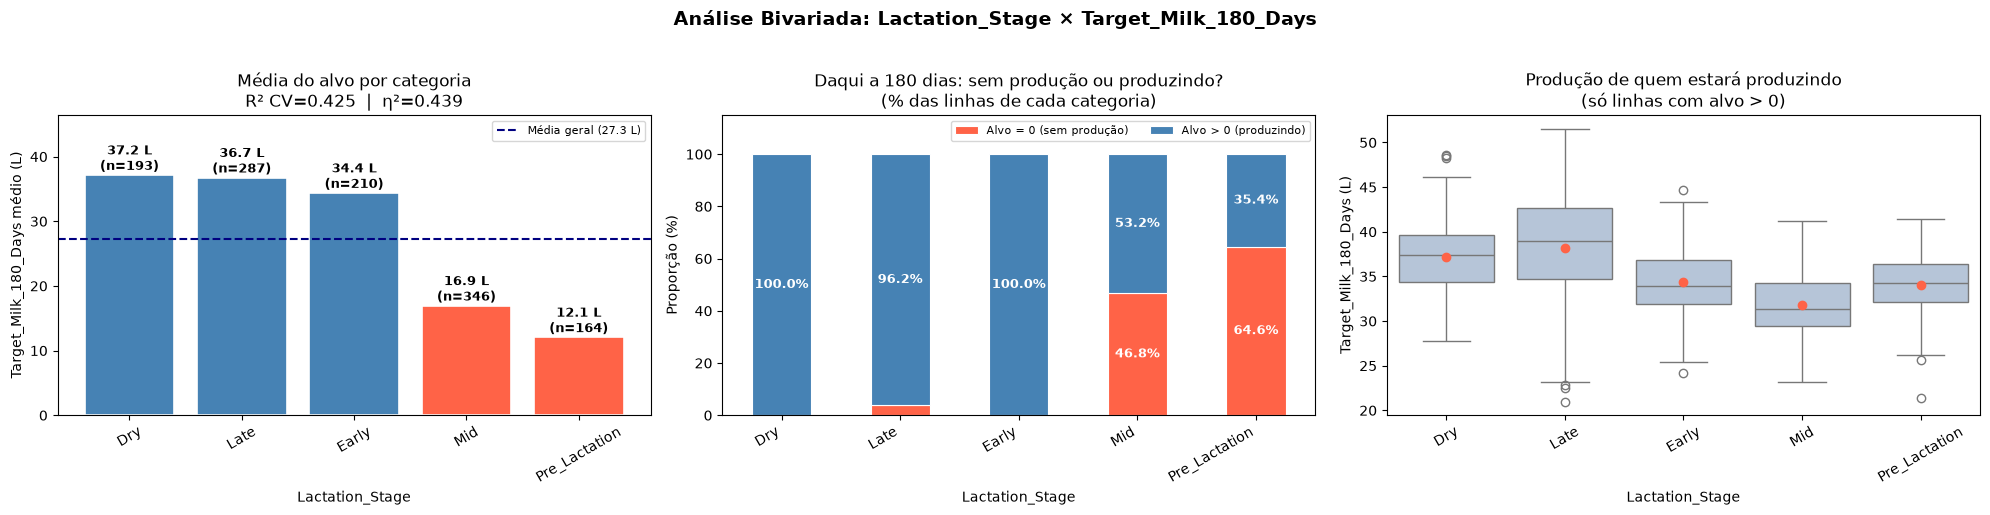

──────────────────────────────────────────────────────────────────────
  Lactation_Stage
  R² CV=0.425  |  η²=0.439  |  🟢 Forte
──────────────────────────────────────────────────────────────────────


,media,pct_zero,N,media_produzindo
Lactation_Stage,,,,
Dry,37.2,0.0,193,37.2
Late,36.7,3.8,287,38.2
Early,34.4,0.0,210,34.4
Mid,16.9,46.8,346,31.9
Pre_Lactation,12.1,64.6,164,34.1


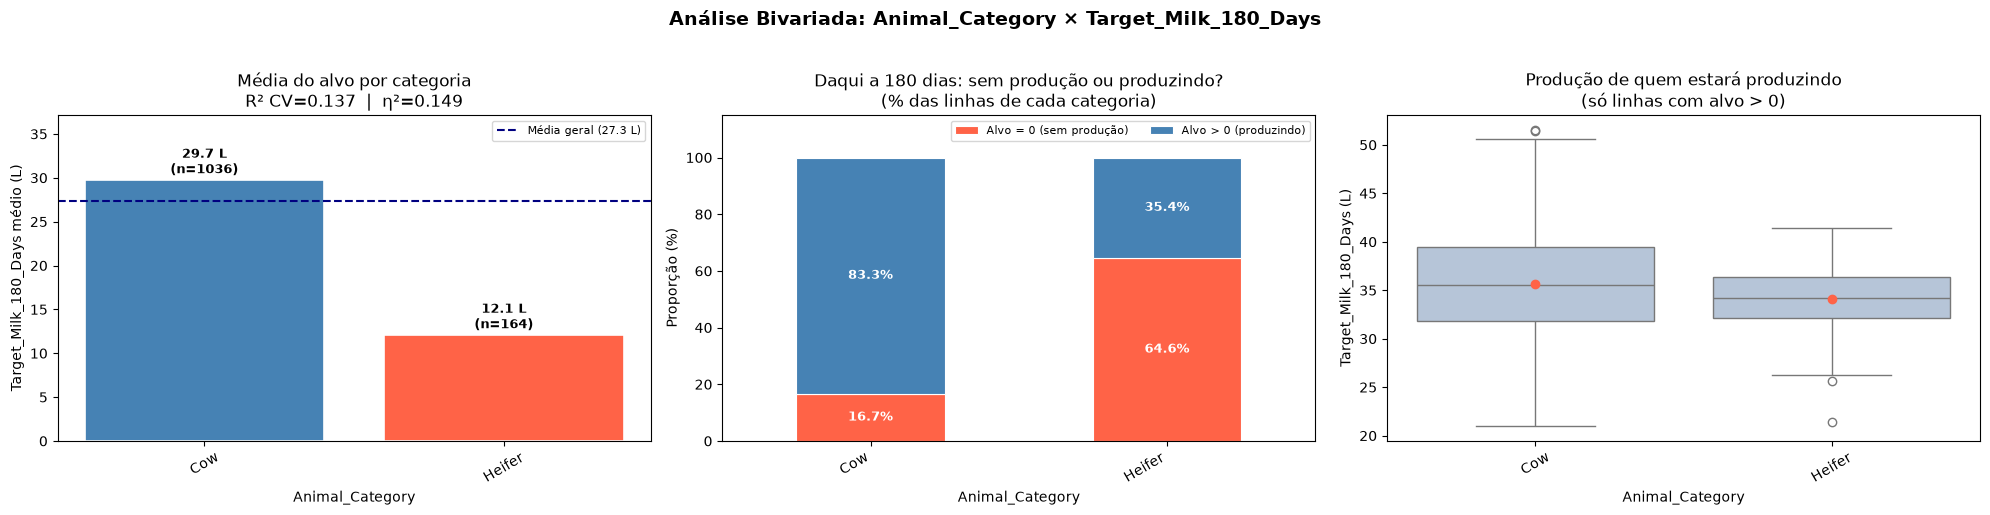

──────────────────────────────────────────────────────────────────────
  Animal_Category
  R² CV=0.137  |  η²=0.149  |  🟡 Moderada
──────────────────────────────────────────────────────────────────────


,media,pct_zero,N,media_produzindo
Animal_Category,,,,
Cow,29.7,16.7,1036,35.7
Heifer,12.1,64.6,164,34.1


In [ ]:
# =======================================================================
# PARTE 1 — Configuração (reaproveita a tabela da univariada categórica)
# =======================================================================

media_geral  = df_train[TARGET].mean()
cols_detalhe = tabela_cat.loc[tabela_cat['Força'] != '🔴 Fraca', 'Feature'].tolist()

for col in cols_detalhe:
    info  = tabela_cat.set_index('Feature').loc[col]
    dados = df_train[[col, TARGET]].copy()
    dados[col] = dados[col].fillna('Missing')
    dados['produz'] = dados[TARGET] > 0

    #============================================================
    # --- Resumo por categoria ---
    #============================================================

    resumo = (
        dados.groupby(col)
        .agg(media=(TARGET, 'mean'),
             pct_zero=('produz', lambda s: (~s).mean() * 100), #taxa de vaca seca/novilha
             N=(TARGET, 'size'))
        .sort_values('media', ascending=False)
    )
    resumo['media_produzindo'] = dados[dados['produz']].groupby(col)[TARGET].mean()
    ordem = resumo.index.tolist()

    #============================================================
    # --- Plots --- Estrutura
    #============================================================

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {TARGET}',
                 fontsize=14, fontweight='bold', y=1.02)

    #============================================================
    # ── Plot 1: Média do alvo por categoria ─────
    #============================================================

    bars = axes[0].bar(
        ordem, resumo['media'],
        color=['steelblue' if v > media_geral else 'tomato' for v in resumo['media']],
        edgecolor='white', linewidth=1.2
    )
    axes[0].axhline(media_geral, color='navy', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({media_geral:.1f} L)')

    for bar, (_, r) in zip(bars, resumo.iterrows()):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.8,
                     f"{r['media']:.1f} L\n(n={int(r['N'])})",
                     ha='center', fontsize=9, fontweight='bold')

    axes[0].set_title(f'Média do alvo por categoria\nR² CV={info["R² CV"]:.3f}  |  η²={info["η²"]:.3f}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel(f'{TARGET} médio (L)')
    axes[0].set_ylim(0, resumo['media'].max() * 1.25)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].legend(loc='upper right', fontsize=8)

    #============================================================
    # ── Plot 2: Stacked Bar 100% — sem produção × produzindo ───
    #============================================================

    pct = pd.DataFrame({
        'Alvo = 0 (sem produção)': resumo['pct_zero'],
        'Alvo > 0 (produzindo)'  : 100 - resumo['pct_zero'],
    })
    pct.plot(kind='bar', stacked=True, ax=axes[1],
             color=['tomato', 'steelblue'], edgecolor='white', linewidth=0.8)

    for i, (_, r) in enumerate(pct.iterrows()):
        zero, prod = r['Alvo = 0 (sem produção)'], r['Alvo > 0 (produzindo)']
        if zero >= 4:
            axes[1].text(i, zero / 2, f'{zero:.1f}%', ha='center', va='center',
                         color='white', fontsize=9, fontweight='bold')
        if prod >= 4:
            axes[1].text(i, zero + prod / 2, f'{prod:.1f}%', ha='center', va='center',
                         color='white', fontsize=9, fontweight='bold')

    axes[1].set_title('Daqui a 180 dias: sem produção ou produzindo?\n(% das linhas de cada categoria)')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Proporção (%)')
    axes[1].set_xticklabels(ordem, rotation=30, ha='right')
    axes[1].set_ylim(0, 115)
    axes[1].legend(loc='upper right', fontsize=8, ncol=2)

    #============================================================
    # ── Plot 3: Boxplot só de quem estará produzindo ───────────────
    #============================================================

    sns.boxplot(data=dados[dados['produz']], x=col, y=TARGET, order=ordem, ax=axes[2],
                color='lightsteelblue', showmeans=True,
                meanprops=dict(marker='o', markerfacecolor='tomato', markeredgecolor='tomato'))

    axes[2].set_title('Produção de quem estará produzindo\n(só linhas com alvo > 0)')
    axes[2].set_xlabel(col)
    axes[2].set_ylabel(f'{TARGET} (L)')
    axes[2].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    #============================================================
    # --- Resumo textual ---
    #============================================================

    print(f"{'─'*70}")
    print(f"  {col}")
    print(f"  R² CV={info['R² CV']:.3f}  |  η²={info['η²']:.3f}  |  {info['Força']}")
    print(f"{'─'*70}")
    display(resumo.round(1))


# Análise Bivariada Categórica para Regressão — Explicação do Código

A univariada categórica respondeu **quanto** cada categórica explica o alvo (`tabela_cat`). A bivariada abre as que importam para ver **de onde vem** essa diferença. Como o alvo tem muitos zeros (vacas sem produção daqui a 180 dias), a média de cada categoria é separada em duas partes:

```
média = (% produzindo) × (produção média de quem está produzindo)
```

Cada gráfico mostra uma parte: o Plot 1 a média, o Plot 2 a chance de estar sem produzir e o Plot 3 quanto produz quem está produzindo.

## PARTE 1 — Configuração

```python
media_geral  = df_train[TARGET].mean()
cols_detalhe = tabela_cat.loc[tabela_cat['Força'] != '🔴 Fraca', 'Feature'].tolist()

for col in cols_detalhe:
    info  = tabela_cat.set_index('Feature').loc[col]
    dados = df_train[[col, TARGET]].copy()
    dados[col]      = dados[col].fillna('Missing')
    dados['produz'] = dados[TARGET] > 0
```

- **`media_geral`**: a média do alvo em todo o `df_train`, usada como linha de referência.
- **`cols_detalhe`**: só as categóricas que **não** são Fracas na univariada. As fracas já apareceram nos gráficos da univariada como médias todas parecidas.
- **`info`**: a linha da feature atual na `tabela_cat`, com o R² CV, o η² e a Força prontos. Nada é recalculado.
- **`dados`**: a feature e o alvo, numa tabela independente (`.copy()`), para criar colunas novas sem mexer no `df_train`.
- **`fillna('Missing')`**: faltantes viram uma categoria própria. Sem isso, o `groupby` descartaria essas linhas sem avisar.
- **`dados['produz'] = dados[TARGET] > 0`**: coluna True/False que marca se a vaca estará produzindo daqui a 180 dias. False = alvo zero (seca ou ainda não pariu).

## Resumo por categoria

```python
    resumo = (
        dados.groupby(col)
        .agg(media=(TARGET, 'mean'),
             pct_zero=('produz', lambda s: (~s).mean() * 100),
             N=(TARGET, 'size'))
        .sort_values('media', ascending=False)
    )
    resumo['media_produzindo'] = dados[dados['produz']].groupby(col)[TARGET].mean()
    ordem = resumo.index.tolist()
```

- **`groupby(col).agg(...)`**: uma linha por categoria, com três colunas criadas por "agregação nomeada" (`nome=(coluna, função)`):
    - **`media`**: o leite médio da categoria, contando os zeros.
    - **`pct_zero`**: a % de linhas com alvo zero. O `~s` inverte o True/False (True passa a ser "não produz"), e o `.mean()` de True/False é a proporção. Vezes 100, vira porcentagem.
    - **`N`**: quantas linhas a categoria tem. O `'size'` conta as linhas.
- **`sort_values('media', ascending=False)`**: da maior para a menor média.
- **`media_produzindo`**: a média do alvo **só nas linhas com alvo > 0** (`dados[dados['produz']]`), por categoria. Ao ser atribuída como coluna, o pandas encaixa cada valor na categoria certa pelo índice.
- **`ordem`**: a lista das categorias na ordem da média. Os três gráficos usam essa mesma ordem.

## Plots — Estrutura

```python
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {TARGET}', fontsize=14, fontweight='bold', y=1.02)
```

- **`plt.subplots(1, 3, ...)`**: uma linha com três gráficos (`axes[0]`, `axes[1]`, `axes[2]`).
- **`suptitle(..., y=1.02)`**: título geral, um pouco acima para não encostar nos títulos individuais.

## Plot 1 — Média do alvo por categoria

```python
    bars = axes[0].bar(ordem, resumo['media'],
                       color=['steelblue' if v > media_geral else 'tomato' for v in resumo['media']], ...)
    axes[0].axhline(media_geral, ...)

    for bar, (_, r) in zip(bars, resumo.iterrows()):
        axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
                     f"{r['media']:.1f} L\n(n={int(r['N'])})", ...)
```

- **`color=[... for v in ...]`**: list comprehension que escolhe a cor de cada barra. **Azul** se a média está acima da geral, **vermelho** se está abaixo.
- **`axhline(media_geral)`**: linha tracejada com a média geral.
- **`zip(bars, resumo.iterrows())`**: percorre ao mesmo tempo cada barra e a linha correspondente do `resumo`. O `iterrows()` devolve pares (índice, linha); o `_` descarta o índice.
- **`bar.get_x() + bar.get_width() / 2`**: o centro horizontal da barra, onde o texto é escrito.
- **`bar.get_height() + 0.8`**: um pouco acima do topo da barra.
- **Texto**: a média em litros e o **n**. O n avisa quando uma categoria é pequena demais para confiar na média.
- **`set_ylim(0, ... * 1.25)`**: 25% de espaço acima da maior barra para o texto caber.

## Plot 2 — Barra empilhada 100%: sem produção × produzindo

```python
    pct = pd.DataFrame({
        'Alvo = 0 (sem produção)': resumo['pct_zero'],
        'Alvo > 0 (produzindo)'  : 100 - resumo['pct_zero'],
    })
    pct.plot(kind='bar', stacked=True, ax=axes[1], color=['tomato', 'steelblue'], ...)

    for i, (_, r) in enumerate(pct.iterrows()):
        zero, prod = r['Alvo = 0 (sem produção)'], r['Alvo > 0 (produzindo)']
        if zero >= 4:
            axes[1].text(i, zero / 2, f'{zero:.1f}%', ...)
        if prod >= 4:
            axes[1].text(i, zero + prod / 2, f'{prod:.1f}%', ...)
```

- **`pct`**: uma tabela com duas colunas que somam 100% em cada categoria.
- **`plot(kind='bar', stacked=True)`**: barras empilhadas. Vermelho embaixo (sem produção), azul em cima (produzindo).
- **`enumerate(pct.iterrows())`**: dá a posição da barra (`i` = 0, 1, 2…) e os valores da linha.
- **`zero / 2`**: o meio do pedaço vermelho, onde o texto é escrito.
- **`zero + prod / 2`**: o meio do pedaço azul (começa onde o vermelho termina).
- **`if zero >= 4`**: só escreve o número se o pedaço tiver pelo menos 4%. Num pedaço menor, o texto não cabe e fica por cima da borda.
- **`set_ylim(0, 115)`**: espaço acima de 100% para a legenda.

> **Por que "sem produção" e não "seca":** o alvo zero junta dois casos. A vaca **seca** (entre lactações) e a **novilha que ainda não pariu**. As duas dão zero, mas por motivos diferentes.

## Plot 3 — Boxplot só de quem estará produzindo

```python
    sns.boxplot(data=dados[dados['produz']], x=col, y=TARGET, order=ordem, ax=axes[2],
                color='lightsteelblue', showmeans=True, meanprops=dict(...))
```

- **`data=dados[dados['produz']]`**: só as linhas com alvo > 0. Os zeros saem, para responder: **"quando produz, produz quanto?"**
- **`order=ordem`**: a mesma ordem de categorias dos outros dois gráficos.
- **`showmeans=True`**: ponto vermelho com a média, o valor da coluna `media_produzindo` do `resumo`.

> **Como ler os três juntos:** se as barras do Plot 1 são muito diferentes, mas as caixas do Plot 3 ficam na mesma altura, a categoria **não muda quanto a vaca produz**: muda **a chance de ela estar sem produzir** (Plot 2). Se as caixas do Plot 3 também mudam de altura, a categoria afeta as duas coisas.

## Resumo textual

```python
    print(...)
    display(resumo.round(1))
```

- **`print`**: as métricas da `tabela_cat` numa linha.
- **`display(resumo.round(1))`**: a tabela com as três partes da média por categoria. É `display` e não `print` para sair como tabela formatada.


## Resultados da Análise Bivariada Categórica

Só duas categóricas passaram do corte de Fraca na univariada: `Lactation_Stage` (🟢 Forte, R² CV 0,425) e `Animal_Category` (🟡 Moderada, R² CV 0,137). As outras quatro (estação, estresse térmico, condição corporal, saúde) têm médias parecidas entre as categorias.

### Lactation_Stage: a fase decide SE a vaca vai produzir, não QUANTO

| Fase hoje | Média (L) | % sem produção daqui a 180 dias | Média de quem produz (L) | n |
|---|---|---|---|---|
| Dry | 37,2 | 0,0 | 37,2 | 193 |
| Late | 36,7 | 3,8 | 38,2 | 287 |
| Early | 34,4 | 0,0 | 34,4 | 210 |
| **Mid** | **16,9** | **46,8** | 31,9 | 346 |
| **Pre_Lactation** | **12,1** | **64,6** | 34,1 | 164 |

As médias vão de 12 a 37 L, mas **entre as vacas que estarão produzindo a diferença é pequena** (de 32 a 38 L). Quase toda a diferença vem da **% sem produção**:

```
Mid:  53,2% produzindo × 31,9 L = 17,0 L  ≈ média de 16,9 L
Dry: 100,0% produzindo × 37,2 L = 37,2 L
```

A leitura pelo ciclo:

- **Dry e Early hoje → 0% sem produção.** Daqui a 180 dias estarão no meio da próxima lactação.
- **Mid hoje → 46,8% sem produção.** Daqui a 180 dias, quase metade estará no período seco.
- **Pre_Lactation (novilhas) → 64,6% sem produção.** A maioria ainda não terá parido daqui a 180 dias. Mas as que tiverem parido produzem 34,1 L, o mesmo nível das vacas adultas.

### Animal_Category: mesma história, dita de outro jeito

| Categoria | Média (L) | % sem produção | Média de quem produz (L) | n |
|---|---|---|---|---|
| Cow | 29,7 | 16,7 | 35,7 | 1.036 |
| Heifer | 12,1 | 64,6 | 34,1 | 164 |

`Heifer` são exatamente as mesmas 164 linhas de `Pre_Lactation`, com os mesmos números. Quando produz, a novilha produz praticamente o mesmo que a vaca adulta (34,1 contra 35,7 L). A diferença de média vem toda de ela ainda não ter parido.

### Conclusões

1. **O problema tem duas partes.** Prever o leite daqui a 180 dias é, na prática, prever **(a) se a vaca estará produzindo** e **(b) quanto**. As categóricas fortes ajudam muito na parte (a) e quase nada na (b).
2. **Isso abre uma opção de modelagem:** um modelo em duas etapas. Um classificador decide "vai produzir ou não" e um regressor, treinado só nas linhas com alvo > 0, decide "quanto". É uma estrutura comum quando o alvo tem muitos zeros (modelos *hurdle* ou *zero-inflated*). Vale comparar com o modelo único no backtesting.
3. **`Animal_Category` não acrescenta nada** a `Lactation_Stage`: manter só uma.
4. **A média sozinha engana nessas features.** "Mid = 16,9 L" não descreve nenhuma vaca real: é uma mistura de vacas com 0 L e vacas com ~32 L.


## 5.3 Análise Multivariada

/tmp/ipykernel_2684/4146176807.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]


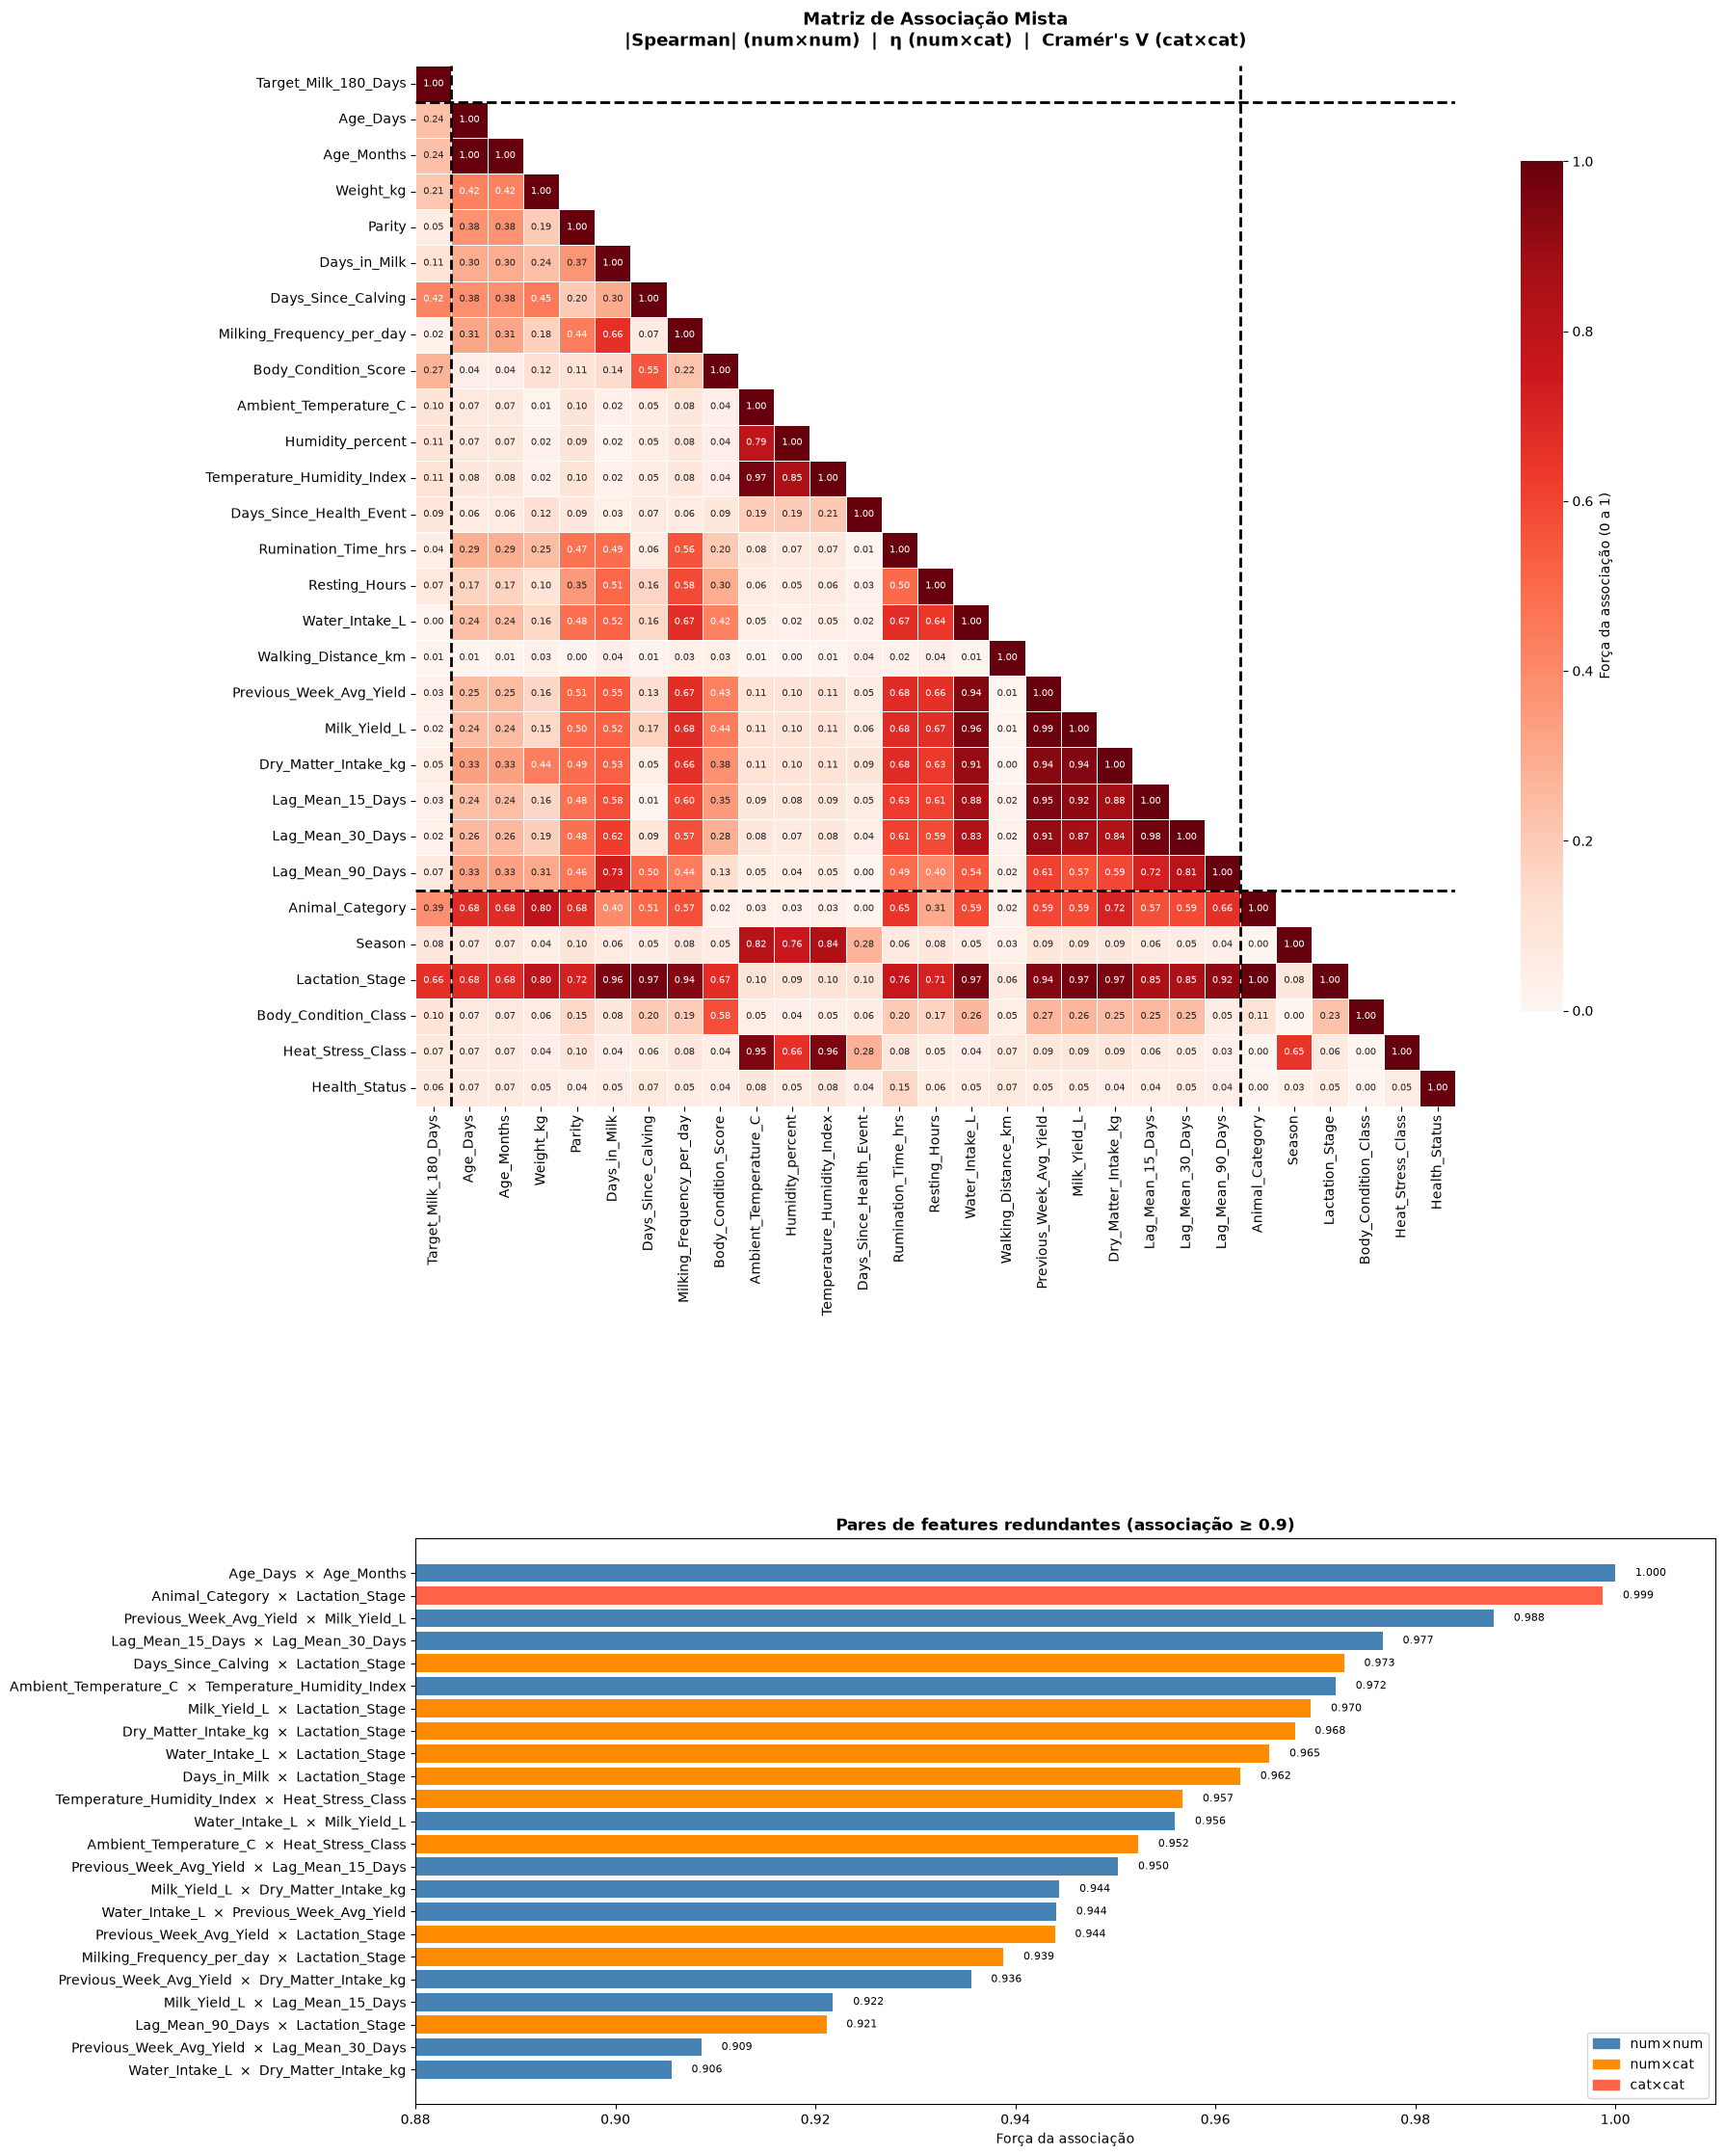


PARES REDUNDANTES (associação ≥ 0.9): 23
Age_Days                    Age_Months                    1.000
Animal_Category             Lactation_Stage               0.999
Previous_Week_Avg_Yield     Milk_Yield_L                  0.988
Lag_Mean_15_Days            Lag_Mean_30_Days              0.977
Days_Since_Calving          Lactation_Stage               0.973
Ambient_Temperature_C       Temperature_Humidity_Index    0.972
Milk_Yield_L                Lactation_Stage               0.970
Dry_Matter_Intake_kg        Lactation_Stage               0.968
Water_Intake_L              Lactation_Stage               0.965
Days_in_Milk                Lactation_Stage               0.962
Temperature_Humidity_Index  Heat_Stress_Class             0.957
Water_Intake_L              Milk_Yield_L                  0.956
Ambient_Temperature_C       Heat_Stress_Class             0.952
Previous_Week_Avg_Yield     Lag_Mean_15_Days              0.950
Milk_Yield_L                Dry_Matter_Intake_kg          0.94

In [33]:
from matplotlib.patches import Patch

# ================================================
# PARTE 1 — Colunas e função η (numérica × categórica)
# ================================================

num_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c != TARGET]
cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]
all_cols = [TARGET] + num_cols + cat_cols

def correlation_ratio(cat, num):
    medias = num.groupby(cat).mean()
    n      = cat.value_counts()
    eta2   = (n * (medias - num.mean()) ** 2).sum() / ((num - num.mean()) ** 2).sum()
    return np.sqrt(eta2)

# ================================================
# PARTE 2 — Matriz de Associação Mista
# ================================================

assoc = pd.DataFrame(np.eye(len(all_cols)), index=all_cols, columns=all_cols)

for i, col_a in enumerate(all_cols):
    for col_b in all_cols[i + 1:]:

        a_is_num = col_a not in cat_cols
        b_is_num = col_b not in cat_cols

        if a_is_num and b_is_num:
            v = abs(df_train[col_a].corr(df_train[col_b], method='spearman'))
        elif not a_is_num and not b_is_num:
            v = cramers_v(df_train[col_a], df_train[col_b])
        else:
            col_cat, col_num = (col_b, col_a) if a_is_num else (col_a, col_b)
            v = correlation_ratio(df_train[col_cat], df_train[col_num])

        assoc.loc[col_a, col_b] = v
        assoc.loc[col_b, col_a] = v

# ================================================
# PARTE 3 — Pares redundantes
# ================================================

LIMIAR = 0.9

def tipo_par(a, b):
    a_cat, b_cat = a in cat_cols, b in cat_cols
    if a_cat and b_cat:   return 'cat×cat'
    elif a_cat or b_cat:  return 'num×cat'
    else:                 return 'num×num'

pares  = assoc.where(np.triu(np.ones(assoc.shape, dtype=bool), k=1)).stack().drop(TARGET, level=0)
fortes = pares[pares >= LIMIAR].sort_values()

# ====================================================================
# ── Visualização: 2 linhas × 1 coluna ───────────
# ====================================================================

fig, axes = plt.subplots(2, 1, figsize=(18, 24), gridspec_kw={'height_ratios': [3, 1.2]})

# ====================================================================
# ── Plot 1: Heatmap completo ────────────────────────────
# ====================================================================

mask = np.triu(np.ones_like(assoc, dtype=bool), k=1)

sns.heatmap(
    assoc,
    mask=mask,
    ax=axes[0],
    cmap='Reds',
    vmin=0, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.4,
    square=True,
    cbar_kws={'label': 'Força da associação (0 a 1)', 'shrink': 0.6}
)

for pos in [1, 1 + len(num_cols)]:
    axes[0].axhline(pos, color='black', linewidth=2, linestyle='--')
    axes[0].axvline(pos, color='black', linewidth=2, linestyle='--')

axes[0].set_title("Matriz de Associação Mista\n|Spearman| (num×num)  |  η (num×cat)  |  Cramér's V (cat×cat)",
                  fontsize=13, fontweight='bold', pad=15)
axes[0].tick_params(axis='x', rotation=90)
axes[0].tick_params(axis='y', rotation=0)

# ====================================================================
# ── Plot 2: Pares redundantes ──────────────────
# ====================================================================

cores   = {'num×num': 'steelblue', 'num×cat': 'darkorange', 'cat×cat': 'tomato'}
rotulos = [f'{a}  ×  {b}' for a, b in fortes.index]

axes[1].barh(rotulos, fortes.values,
             color=[cores[tipo_par(a, b)] for a, b in fortes.index])

for i, v in enumerate(fortes.values):
    axes[1].text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=8)

axes[1].set_title(f'Pares de features redundantes (associação ≥ {LIMIAR})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Força da associação')
axes[1].set_xlim(LIMIAR - 0.02, 1.01)
axes[1].legend(handles=[Patch(color=c, label=t) for t, c in cores.items()], loc='lower right')

plt.tight_layout(h_pad=4)
plt.show()

# ====================================================================
# --- Resumo textual ---
# ====================================================================

print(f"\n{'='*60}")
print(f"PARES REDUNDANTES (associação ≥ {LIMIAR}): {len(fortes)}")
print(f"{'='*60}")
print(fortes.sort_values(ascending=False).round(3).to_string())


# Matriz de Associação Mista para Regressão — Explicação do Código

A matriz mede a associação entre **todos os pares** de colunas (alvo, numéricas e categóricas), cada tipo de par com a medida adequada. O objetivo principal é achar **features redundantes**: pares que carregam quase a mesma informação. O ranking de força com o alvo fica com a univariada (R² CV), que mede isso melhor.

## PARTE 1 — Colunas e função η

```python
num_cols = [c for c in df_train.select_dtypes(include=[np.number]).columns if c != TARGET]
cat_cols = [c for c in df_train.select_dtypes(include=['object', 'category']).columns if c != GRUPO]
all_cols = [TARGET] + num_cols + cat_cols

def correlation_ratio(cat, num):
    medias = num.groupby(cat).mean()
    n      = cat.value_counts()
    eta2   = (n * (medias - num.mean()) ** 2).sum() / ((num - num.mean()) ** 2).sum()
    return np.sqrt(eta2)
```

- **`num_cols`**: numéricas, sem o alvo.
- **`cat_cols`**: categóricas, sem o `Cattle_ID` (é o ID da vaca, não uma feature).
- **`all_cols`**: a ordem das linhas e colunas da matriz: o alvo primeiro, depois as numéricas, depois as categóricas.
- **`correlation_ratio` (η, "eta")**: a associação entre uma categórica e uma numérica.
    - O cálculo de dentro é o **mesmo η² da univariada categórica**: a variação entre as médias das categorias dividida pela variação total.
    - **`np.sqrt(eta2)`**: tira a raiz para ficar na mesma escala de uma correlação (0 a 1), comparável ao |Spearman| e ao Cramér's V.
    - 0 = todas as categorias têm a mesma média da numérica; 1 = a categoria determina a numérica por completo.

> **Por que não Cramér's V para numérica × categórica:** o Cramér's V trabalha com tabelas de contagem. Transformar uma numérica em texto (`.astype(str)`) faz cada valor diferente virar uma categoria (`Weight_kg` viraria 946 categorias), e o resultado sai distorcido. Neste dataset, `Weight_kg × Lactation_Stage` dá 0,177 pelo Cramér's V contra 0,804 pelo η.

## PARTE 2 — Matriz de Associação Mista

```python
assoc = pd.DataFrame(np.eye(len(all_cols)), index=all_cols, columns=all_cols)

for i, col_a in enumerate(all_cols):
    for col_b in all_cols[i + 1:]:
        a_is_num = col_a not in cat_cols
        b_is_num = col_b not in cat_cols

        if a_is_num and b_is_num:
            v = abs(df_train[col_a].corr(df_train[col_b], method='spearman'))
        elif not a_is_num and not b_is_num:
            v = cramers_v(df_train[col_a], df_train[col_b])
        else:
            col_cat, col_num = (col_b, col_a) if a_is_num else (col_a, col_b)
            v = correlation_ratio(df_train[col_cat], df_train[col_num])

        assoc.loc[col_a, col_b] = v
        assoc.loc[col_b, col_a] = v
```

- **`np.eye(n)`**: matriz identidade, com 1 na diagonal (cada coluna consigo mesma) e 0 no resto. Já nasce com a diagonal pronta.
- **`for col_b in all_cols[i + 1:]`**: para cada coluna, percorre só as que vêm **depois** dela. Cada par é calculado **uma vez**, metade do trabalho de percorrer a matriz inteira.
- **`a_is_num`, `b_is_num`**: True se a coluna não é categórica. O alvo conta como numérica.
- **As três medidas**, todas de 0 a 1:

| Par | Medida | O que capta |
|---|---|---|
| num × num | \|Spearman\| | Relação que só sobe ou só desce. O `abs` tira o sinal |
| cat × cat | Cramér's V | Associação entre duas tabelas de categorias |
| num × cat | η | Quanto as médias da numérica mudam entre as categorias |

- **`(col_b, col_a) if a_is_num else (col_a, col_b)`**: decide quem é a categórica e quem é a numérica, porque a função `correlation_ratio` precisa receber as duas na ordem certa.
- **As duas linhas finais**: gravam o valor nos dois lados da matriz (A×B e B×A), que é simétrica.

## PARTE 3 — Pares redundantes

```python
LIMIAR = 0.9

pares  = assoc.where(np.triu(np.ones(assoc.shape, dtype=bool), k=1)).stack().drop(TARGET, level=0)
fortes = pares[pares >= LIMIAR].sort_values()
```

- **`LIMIAR = 0.9`**: a partir de 0,9, os dois lados do par carregam praticamente a mesma informação.
- **`np.triu(..., k=1)`**: máscara do triângulo de cima, **sem a diagonal**, para cada par aparecer uma vez.
- **`.where(...)`**: mantém os valores do triângulo e põe vazio no resto.
- **`.stack()`**: transforma a matriz numa lista de pares (coluna A, coluna B) → valor.
- **`.drop(TARGET, level=0)`**: remove os pares com o alvo. Feature muito associada ao alvo não é redundância, é feature boa.
- **`tipo_par(a, b)`**: devolve o tipo do par (`num×num`, `num×cat` ou `cat×cat`), usado para pintar as barras.

## Plot 1 — Heatmap

```python
mask = np.triu(np.ones_like(assoc, dtype=bool), k=1)
sns.heatmap(assoc, mask=mask, cmap='Reds', vmin=0, vmax=1, annot=True, fmt='.2f', ...)

for pos in [1, 1 + len(num_cols)]:
    axes[0].axhline(pos, ...)
    axes[0].axvline(pos, ...)
```

- **`mask`**: esconde o triângulo de cima, que é espelho do de baixo.
- **`cmap='Reds'`, `vmin=0`, `vmax=1`**: uma só escala, do branco (sem associação) ao vermelho escuro (associação total). Como todas as medidas vão de 0 a 1, as cores são comparáveis entre os três tipos de par.
- **`annot=True, fmt='.2f'`**: escreve o valor em cada célula, com 2 casas decimais.
- **Linhas tracejadas**: separam os três blocos. A posição 1 separa o alvo das numéricas; a posição `1 + len(num_cols)` separa as numéricas das categóricas.

## Plot 2 — Pares redundantes

```python
axes[1].barh(rotulos, fortes.values, color=[cores[tipo_par(a, b)] for a, b in fortes.index])
axes[1].set_xlim(LIMIAR - 0.02, 1.01)
axes[1].legend(handles=[Patch(color=c, label=t) for t, c in cores.items()], loc='lower right')
```

- **`barh`**: barras horizontais, porque os nomes dos pares são longos e ficam legíveis no eixo vertical.
- **`color=[...]`**: azul para num×num, laranja para num×cat, vermelho para cat×cat.
- **`set_xlim(LIMIAR - 0.02, 1.01)`**: o eixo começa perto do limiar. Como todos os valores estão entre 0,9 e 1, começar do 0 deixaria todas as barras com o mesmo tamanho aparente.
- **`Patch(color=c, label=t)`**: cria à mão os quadradinhos coloridos da legenda. Como cada barra tem uma cor diferente numa chamada só, o matplotlib não monta a legenda sozinho.


## Resultados da Matriz de Associação

**23 pares** com associação ≥ 0,9. Eles formam quatro grupos de informação repetida:

### 1. Lactation_Stage é um "resumo" de várias numéricas

| Par | Associação (η) |
|---|---|
| Days_Since_Calving × Lactation_Stage | 0,973 |
| Milk_Yield_L × Lactation_Stage | 0,970 |
| Dry_Matter_Intake_kg × Lactation_Stage | 0,968 |
| Water_Intake_L × Lactation_Stage | 0,965 |
| Days_in_Milk × Lactation_Stage | 0,962 |
| Previous_Week_Avg_Yield × Lactation_Stage | 0,944 |
| Milking_Frequency_per_day × Lactation_Stage | 0,939 |
| Lag_Mean_90_Days × Lactation_Stage | 0,921 |

A fase da lactação é praticamente o `Days_in_Milk` cortado em faixas, e tudo o que depende da fase (produção do dia, consumo, água, frequência de ordenha) acompanha junto. Esses pares só apareceram agora: a checagem de redundância da univariada numérica não comparava numéricas com categóricas.

### 2. Medidas de produção recente

| Par | Associação |
|---|---|
| Previous_Week_Avg_Yield × Milk_Yield_L | 0,988 |
| Lag_Mean_15_Days × Lag_Mean_30_Days | 0,977 |
| Water_Intake_L × Milk_Yield_L | 0,956 |
| Previous_Week_Avg_Yield × Lag_Mean_15_Days | 0,950 |
| Milk_Yield_L × Dry_Matter_Intake_kg | 0,944 |

Produção do dia, da semana, médias de 15 e 30 dias, água e consumo medem quase a mesma coisa: **quanto a vaca está produzindo agora**.

### 3. Clima

| Par | Associação |
|---|---|
| Ambient_Temperature_C × Temperature_Humidity_Index | 0,972 |
| Temperature_Humidity_Index × Heat_Stress_Class | 0,957 |
| Ambient_Temperature_C × Heat_Stress_Class | 0,952 |

O THI é calculado a partir da temperatura, e a `Heat_Stress_Class` é o THI cortado em faixas. Na prática, é uma variável só (e fraca com o alvo).

### 4. Duplicatas exatas

| Par | Associação |
|---|---|
| Age_Days × Age_Months | 1,000 |
| Animal_Category × Lactation_Stage | 0,999 |

Mesma informação em formatos diferentes. Basta uma de cada par.

### Conclusões

1. **Muitas features, poucas informações.** As 28 features se resumem em alguns blocos: fase do ciclo (`Days_in_Milk`, `Days_Since_Calving`, `Lactation_Stage`), produção atual (`Milk_Yield_L` e semelhantes), histórico longo (`Lag_Mean_90_Days`), novilha ou não (`Parity`, `Age`, `Weight`) e clima.
2. **Candidatas a remover**: `Age_Days` (fica `Age_Months`), `Animal_Category`, `Heat_Stress_Class` e `Temperature_Humidity_Index` (fica a temperatura), além de uma ou duas das medidas de produção recente.
3. **Para modelos de árvore**, a redundância não piora a previsão, mas divide a importância entre as features do par e confunde a interpretação. **Para modelos lineares**, deixa os coeficientes instáveis.
4. **Antes de remover, testar no modelo:** tirar cada grupo e ver se o erro do backtesting muda.


# 6.0 Preparação dos Dados

## 6.1 Seleção das Variáveis

In [35]:
# =============================================================
# ---------------- Wrapper Methods (Boruta) -------------------
# =============================================================

"""No Boruta, cada feature ganha uma cópia "sombra" com os valores embaralhados
(mesma distribuição, nenhuma relação com o alvo). A cada rodada, um Random Forest
é treinado com as originais + as sombras, e cada original é comparada com a MELHOR
sombra. Ao fim de várias rodadas, um teste estatístico sobre quantas vezes cada
original venceu decide: confirmada, tentativa ou rejeitada."""

# =============================================================
# --- Preparação dos dados ---
# =============================================================

x = df_train.drop(columns=[TARGET, GRUPO, 'Date'])
y = df_train[TARGET]

x_boruta = pd.get_dummies(x, prefix_sep='__SEP__', dtype=int)

def to_original(col):
    return col.split('__SEP__')[0]

# =============================================================
# --- Modelo e Boruta ---
# =============================================================

rf = RandomForestRegressor(n_jobs=-1, max_depth=5, random_state=42)

boruta = BorutaPy(
    rf,
    n_estimators='auto',
    verbose=0,
    random_state=42
).fit(x_boruta.values, y.values)

# =============================================================
# --- Resultados por dummy ---
# =============================================================

confirmed_boruta = x_boruta.columns[boruta.support_].tolist()
tentative_boruta = x_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta  = x_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

# =============================================================
# --- Volta para o nome original (junta as dummies) ---
# =============================================================

confirmed_boruta = sorted(set(to_original(c) for c in confirmed_boruta))
tentative_boruta = sorted(set(to_original(c) for c in tentative_boruta))
rejected_boruta  = sorted(set(to_original(c) for c in rejected_boruta))

tentative_boruta = [c for c in tentative_boruta if c not in confirmed_boruta]
rejected_boruta  = [c for c in rejected_boruta
                    if c not in confirmed_boruta and c not in tentative_boruta]

# =============================================================
# --- Resumo ---
# =============================================================

ranking = pd.Series(boruta.ranking_, index=x_boruta.columns).sort_values()

print(f'Confirmadas ({len(confirmed_boruta)}): {confirmed_boruta}')
print(f'Tentativas  ({len(tentative_boruta)}): {tentative_boruta}')
print(f'Rejeitadas  ({len(rejected_boruta)}): {rejected_boruta}')
display(ranking.to_frame('Ranking Boruta'))


Confirmadas (14): ['Age_Days', 'Age_Months', 'Days_Since_Calving', 'Days_in_Milk', 'Dry_Matter_Intake_kg', 'Lactation_Stage', 'Lag_Mean_15_Days', 'Lag_Mean_30_Days', 'Lag_Mean_90_Days', 'Milk_Yield_L', 'Parity', 'Previous_Week_Avg_Yield', 'Water_Intake_L', 'Weight_kg']
Tentativas  (0): []
Rejeitadas  (14): ['Ambient_Temperature_C', 'Animal_Category', 'Body_Condition_Class', 'Body_Condition_Score', 'Days_Since_Health_Event', 'Health_Status', 'Heat_Stress_Class', 'Humidity_percent', 'Milking_Frequency_per_day', 'Resting_Hours', 'Rumination_Time_hrs', 'Season', 'Temperature_Humidity_Index', 'Walking_Distance_km']


,Ranking Boruta
Age_Days,1
Age_Months,1
Weight_kg,1
Parity,1
Days_in_Milk,1
Days_Since_Calving,1
Water_Intake_L,1
Previous_Week_Avg_Yield,1
Lactation_Stage__SEP__Mid,1
Lactation_Stage__SEP__Late,1


In [36]:
#============================================
#---------Ajuste Fino Manualmente------------
#============================================

features_select = [['Age_Days', 'Ambient_Temperature_C', 'Days_Since_Calving', 'Days_in_Milk', 'Dry_Matter_Intake_kg', 'Lactation_Stage', 'Lag_Mean_15_Days', 'Lag_Mean_30_Days', 'Lag_Mean_90_Days', 'Milk_Yield_L', 'Parity', 'Previous_Week_Avg_Yield', 'Water_Intake_L', 'Weight_kg']]

# 6.2 Preparação de Variáveis: Transformação, Escalonamento e Encoding (Transformação (Assimetria - log/YJ), Rescaling (Normalização/Padronização) e Encorders)